# Reconocimiento de jugadores: arquetipos y huella de estilo

Evaluación del reconocimiento de jugadores en **League of Legends (Diamante+ / Master+, LAS)** en torno a dos preguntas (PROJECT_SUMMARY §9.S.53, §9.S.58 y §10):

| | Arquetipos (Sección 1) | Huella de estilo (Secciones 2 a 5) |
| :--- | :--- | :--- |
| **Pregunta** | ¿Los jugadores se agrupan en *tipos* discretos? | ¿Cada persona juega de forma *propia* aunque cambie de campeón? |
| **Unidad** | Un perfil promedio por jugador | Múltiples partidas por jugador (propio vs. ajenos y subgrupos intra-cuenta) |
| **Evaluación** | Silhouette, estabilidad, ruido (HDBSCAN) | Reidentificación (AUC), verificación (EER, TAR@1 %) y patrones huella + WR |
| **Respuesta** | **No.** El estilo es un continuo. | **Sí.** Generaliza a no vistos (ROC-AUC 0,963) y separa rachas de posibles cambios de mano. |

En la Sección 6 se verifica además si el estilo aporta al modelo de victoria (**no suma**: identifica personas, no resultados).

**Datos.** *Sección 1:* jugadores con $\ge 50$ partidas y firma de pool (`players.csv`, $N = 14.249$). *Secciones 2–5:* solo **train** Master+ de LAS (`data/splits/train/full_dataset.csv`, 189.076 partidas, 8.997 jugadores) y, con hábitos de timeline, las 100.049 partidas con timeline completo (`data/analysis/huella/`). **El test no se toca.** *Sección 6:* bloques temporales y V Master+.

In [1]:
import json
import sqlite3
import sys
from contextlib import closing
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.gridspec import GridSpec
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from scipy.spatial.distance import cdist
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
for p in (ROOT, ROOT / "scripts" / "analysis"):
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))

from src.features.fingerprint import (  # noqa: E402
    CANONICAL_LANES, STYLE_FEATURES, TIER_ORDER,
    make_halves, player_variance_share, profiles, residualize, row_auc,
)
from fingerprint_level1 import load_train, player_info, subsample  # noqa: E402

DATA = ROOT / "data"
TRAIN = DATA / "splits" / "train" / "full_dataset.csv"
ANALYSIS = DATA / "analysis"
HUELLA = ANALYSIS / "huella"

# Paleta y estilo editorial compartido con eda_modelos_ganador y eda_entre_fotos
CATEGORICAL = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, INK_2, MUTED, BORDER = "#0b0b0b", "#52514e", "#898781", "#c3c2b7"
RESALTE = "background-color: #d8e8f8; color: #0b0b0b; font-weight: bold"
DIVERGENTE = LinearSegmentedColormap.from_list("div", ["#2a78d6", "#f4f3ef", "#e34948"])

sns.set_theme(context="notebook", style="whitegrid", palette=CATEGORICAL)
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": BORDER, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titleweight": "bold", "axes.titlesize": 11.5,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "xtick.color": INK_2, "ytick.color": INK_2, "text.color": INK,
    "legend.frameon": False, "figure.dpi": 110,
})

LANE_LABELS = {"TOP": "Top", "JUNGLE": "Jungla", "MIDDLE": "Mid", "BOTTOM": "ADC", "UTILITY": "Soporte"}
LANE_COLORS = dict(zip(CANONICAL_LANES, [CATEGORICAL[0], CATEGORICAL[5], CATEGORICAL[3], CATEGORICAL[7], CATEGORICAL[6]]))
TIER_LABELS = {"DIAMOND": "Diamond", "MASTER": "Master", "GRANDMASTER": "GM", "CHALLENGER": "Challenger"}

# Nombres legibles para estadísticas y hábitos
FEAT_LABELS = {
    "kills_pm": "Kills / min", "deaths_pm": "Muertes / min", "assists_pm": "Asistencias / min",
    "kill_participation_pct": "% Part. kills", "damage_share_pct": "% Daño equipo",
    "gold_share_pct": "% Oro equipo", "damage_pm": "Daño / min", "damage_taken_pm": "Daño recibido / min",
    "gold_pm": "Oro / min", "cs_pm": "CS / min", "vision_pm": "Visión / min",
    "cs_10": "CS @10", "gold_10": "Oro @10", "xp_10": "XP @10", "damage_10": "Daño @10",
    "early_aggression_10": "Agresión @10", "kills_10": "Kills @10", "deaths_10": "Muertes @10",
    "assists_10": "Asistencias @10", "cs_15": "CS @15", "gold_15": "Oro @15",
    "xp_15": "XP @15", "damage_15": "Daño @15",
    "control_wards_15": "Control wards @15", "wards_puestos_10": "Wards puestos @10",
    "wards_rotos_15": "Wards rotos @15", "max_q": "Maxea Q primero", "max_w": "Maxea W primero",
    "max_e": "Maxea E primero", "l1_q": "Nivel 1: Q", "l1_w": "Nivel 1: W", "l1_e": "Nivel 1: E",
    "primera_vuelta_min": "1.ª vuelta a base (min)", "visitas_tienda_10": "Visitas tienda @10",
    "nivel6_min": "Minuto nivel 6", "oro_sin_gastar_med": "Oro sin gastar (med.)",
    "movimiento_2_10": "Movimiento 2–10", "avance_5_10": "Avance 5–10",
    "primera_muerte_min": "1.ª muerte (min)", "placas_14": "Placas @14", "control_15": "Control mapa @15",
}


def dibujar_flechas_biplot(ax, load, lbls, spread, fontsize=7.6, factor=1.0):
    # Dibuja flechas de cargas PCA y separa etiquetas cercanas para evitar superposiciones.
    sc = factor * spread / np.abs(load).max()
    pts = load * sc
    pos = pts * 1.15
    # Repulsión iterativa suave en y (y leve en x) para despegar etiquetas colineales
    min_dx, min_dy = 0.58 * spread, 0.21 * spread
    for _ in range(60):
        for i in range(len(pos)):
            for j in range(i + 1, len(pos)):
                dx, dy = pos[i, 0] - pos[j, 0], pos[i, 1] - pos[j, 1]
                if abs(dx) < min_dx and abs(dy) < min_dy:
                    push = 0.5 * (min_dy - abs(dy)) + 0.02 * spread
                    sgn = 1.0 if dy >= 0 else -1.0
                    pos[i, 1] += sgn * push
                    pos[j, 1] -= sgn * push
    for i, lbl in enumerate(lbls):
        lx, ly = pts[i]
        tx, ty = pos[i]
        ax.annotate("", xy=(lx, ly), xytext=(0, 0),
                    arrowprops=dict(arrowstyle="->", color=INK, lw=1.1, alpha=0.82))
        ha = "left" if tx >= 0 else "right"
        ax.text(tx, ty, lbl, fontsize=fontsize, fontweight="bold", color=INK, ha=ha, va="center",
                bbox=dict(boxstyle="round,pad=0.12", facecolor="#fcfcfb", edgecolor="none", alpha=0.84))

# 1. ¿Hay tipos de jugadores?

## 1.1 Clustering global (10 variables de estilo)

Evaluamos con K-Means si los jugadores maduros ($\ge 50$ partidas, $N = 14.249$) se agrupan en arquetipos discretos sobre **10 variables puramente de estilo**: especialización de rol, dispersión del pool (`pool_dispersion` del embedding), farmeo (`CS @15`, `Total CS`), cuotas de oro y daño, daño recibido, agresión temprana `@10`, participación en kills y visión.

Se excluyen las diferencias frente al rival porque miden *fuerza* (correlación $+0{,}20$ a $+0{,}38$ con winrate), no *estilo*. El $k$ se elige por silhouette máximo en $k \in [2, 8]$ y se calcula el estadístico de Hopkins ($H > 0{,}70$ indica tendencia a agruparse).

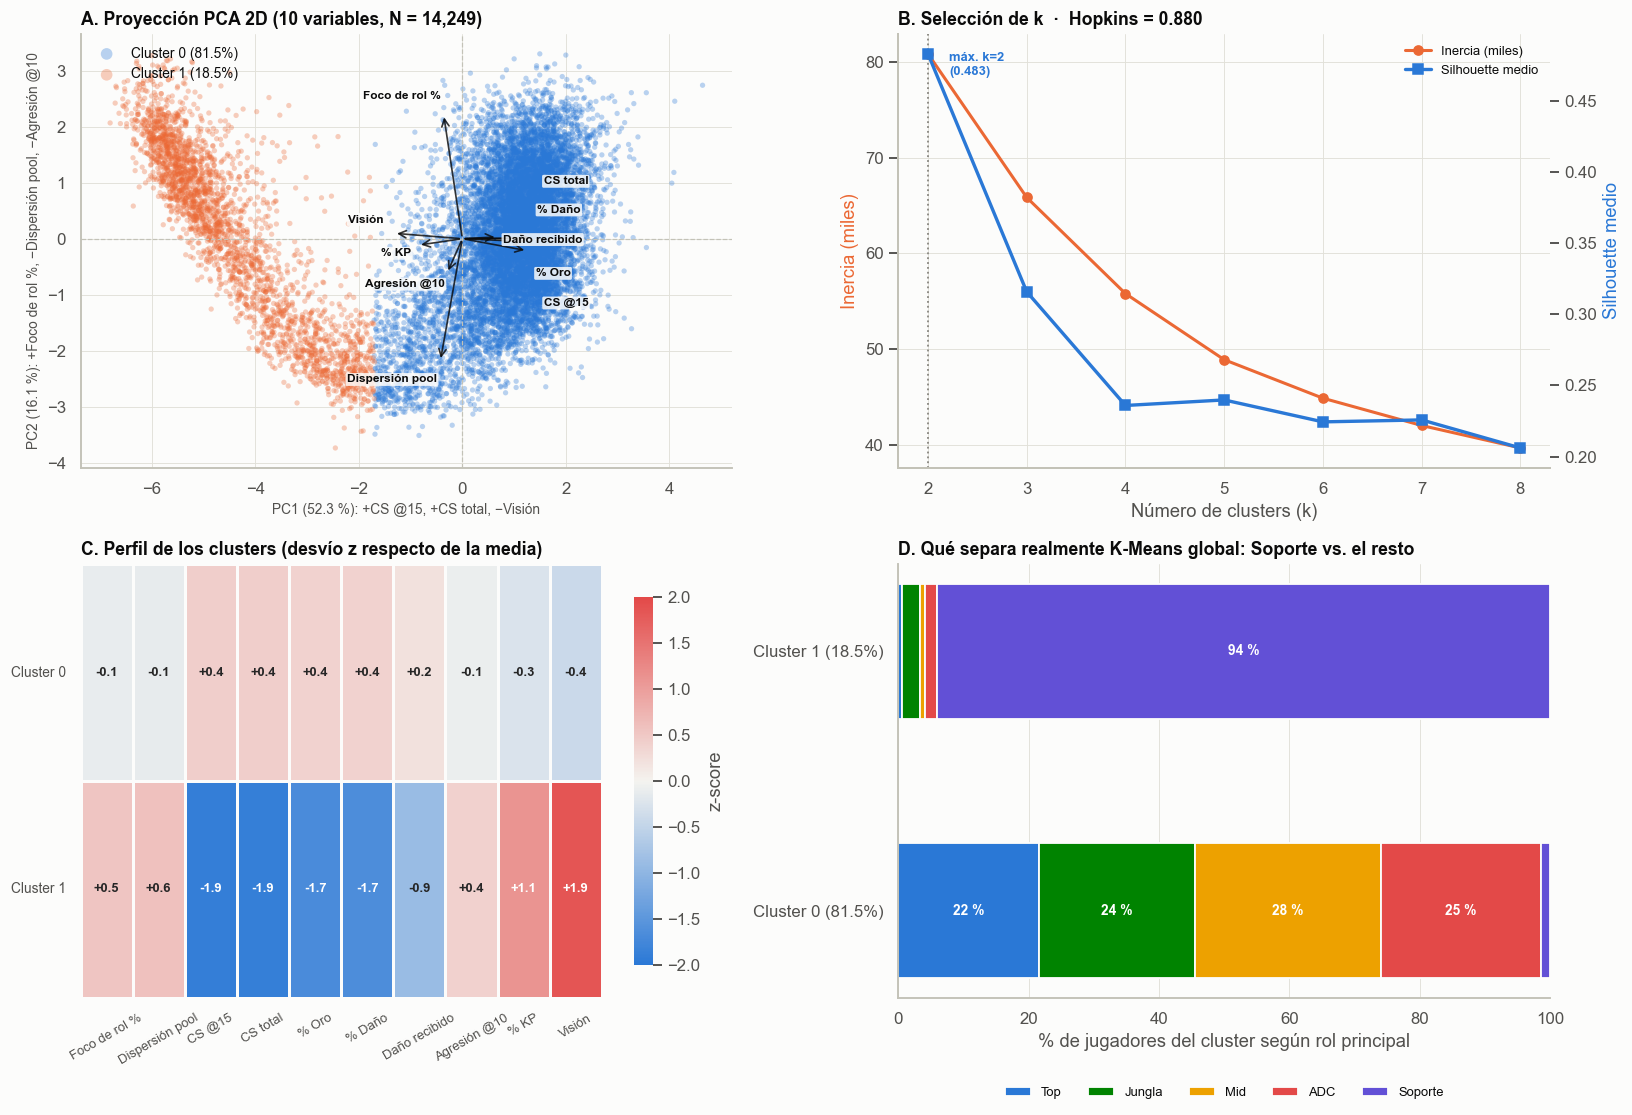

In [2]:
MIN_GAMES, SEED = 50, 42
K_RANGE = list(range(2, 9))

df_players = pd.read_csv(DATA / "players.csv")
df_sig = pd.read_csv(DATA / "player_signatures_A.csv", usecols=["player_id", "pool_dispersion"])
mature = df_players[df_players["games_recorded"] >= MIN_GAMES].merge(df_sig, on="player_id", how="inner")

FEATURES_G = {
    "role_focus_pct": "Foco de rol %", "pool_dispersion": "Dispersión pool",
    "avg_cs_at_15": "CS @15", "avg_total_cs": "CS total", "avg_gold_share_pct": "% Oro",
    "avg_damage_share_pct": "% Daño", "avg_damage_taken": "Daño recibido",
    "avg_early_aggression_10": "Agresión @10", "avg_kill_participation_pct": "% KP",
    "avg_vision_score": "Visión",
}
feats_g = list(FEATURES_G)
labels_g = [FEATURES_G[f] for f in feats_g]
mature = mature.dropna(subset=feats_g).reset_index(drop=True)

scaler_g = StandardScaler()
Xg = scaler_g.fit_transform(mature[feats_g].to_numpy())

# Estadístico de Hopkins (excluyendo la propia distancia en la columna exacta del punto muestreado)
rng_h = np.random.default_rng(SEED)


def hopkins(X_data, n_samples=100, reps=15, rng=None):
    vals = []
    n, d = X_data.shape
    lo, hi = X_data.min(axis=0), X_data.max(axis=0)
    for _ in range(reps):
        idx = rng.choice(n, n_samples, replace=False)
        U = rng.uniform(lo, hi, (n_samples, d))
        dx = cdist(X_data[idx], X_data)
        dx[np.arange(n_samples), idx] = np.inf
        w, u = dx.min(axis=1), cdist(U, X_data).min(axis=1)
        vals.append(u.sum() / (u.sum() + w.sum()))
    return float(np.mean(vals))


h_val = hopkins(Xg, rng=rng_h)

inertias, silhouettes = [], []
for k in K_RANGE:
    km_k = KMeans(n_clusters=k, random_state=SEED, n_init=10)
    lbl_k = km_k.fit_predict(Xg)
    inertias.append(km_k.inertia_)
    silhouettes.append(silhouette_score(Xg, lbl_k))

k_opt = K_RANGE[int(np.argmax(silhouettes))]
km_g = KMeans(n_clusters=k_opt, random_state=SEED, n_init=15)
mature["cluster"] = km_g.fit_predict(Xg)
# Orden consistente: cluster más grande primero (no-soporte), segundo el minoritario (soporte)
order_c = mature["cluster"].value_counts().index.tolist()
remap = {old: new for new, old in enumerate(order_c)}
mature["cluster"] = mature["cluster"].map(remap)

pca_g = PCA(n_components=2)
X_pca_g = pca_g.fit_transform(Xg)
var_g = pca_g.explained_variance_ratio_ * 100
load_g = pca_g.components_.T

z_cent = pd.DataFrame(
    [((mature.loc[mature["cluster"] == c, feats_g].mean() - mature[feats_g].mean())
      / mature[feats_g].std()).values for c in range(k_opt)],
    index=[f"Cluster {c}" for c in range(k_opt)], columns=labels_g,
)
counts_g = mature["cluster"].value_counts().sort_index()
c_titles = {c: f"Cluster {c} ({counts_g[c] / len(mature):.1%})" for c in range(k_opt)}

def pca_axis(j, load, var, lbls):
    top = np.argsort(-np.abs(load[:, j]))[:3]
    parts = [f"{'+' if load[i, j] >= 0 else '−'}{lbls[i]}" for i in top]
    return f"PC{j + 1} ({var[j]:.1f} %): " + ", ".join(parts)

fig, axes = plt.subplots(2, 2, figsize=(15, 10.2))

# Panel A: PCA 2D biplot
ax = axes[0, 0]
for c in range(k_opt):
    mk = mature["cluster"].to_numpy() == c
    ax.scatter(X_pca_g[mk, 0], X_pca_g[mk, 1], color=CATEGORICAL[c], label=c_titles[c],
               alpha=0.32, s=12, edgecolors="none")
spread = np.percentile(np.abs(X_pca_g), 95, axis=0).min()
dibujar_flechas_biplot(ax, load_g, labels_g, spread, fontsize=7.8, factor=0.92)
ax.axhline(0, color=BORDER, ls="--", lw=0.8)
ax.axvline(0, color=BORDER, ls="--", lw=0.8)
ax.set_xlabel(pca_axis(0, load_g, var_g, labels_g), fontsize=9)
ax.set_ylabel(pca_axis(1, load_g, var_g, labels_g), fontsize=9)
ax.set_title(f"A. Proyección PCA 2D ({len(feats_g)} variables, N = {len(mature):,})", loc="left")
ax.legend(markerscale=2.2, loc="upper left", fontsize=9)

# Panel B: Codo y silhouette
ax = axes[0, 1]
ax2 = ax.twinx()
ax2.spines["top"].set_visible(False)
ax2.spines["right"].set_color(BORDER)
ax2.grid(False)
l1 = ax.plot(K_RANGE, np.array(inertias) / 1000, marker="o", color=CATEGORICAL[1], lw=2, label="Inercia (miles)")
l2 = ax2.plot(K_RANGE, silhouettes, marker="s", color=CATEGORICAL[0], lw=2.2, label="Silhouette medio")
ax.axvline(k_opt, color=MUTED, ls=":", lw=1.2)
ax2.annotate(f"máx. k={k_opt}\n({max(silhouettes):.3f})", (k_opt, max(silhouettes)),
             xytext=(14, -14), textcoords="offset points", fontsize=8.5, fontweight="bold", color=CATEGORICAL[0])
ax.set_xlabel("Número de clusters (k)")
ax.set_ylabel("Inercia (miles)", color=CATEGORICAL[1])
ax2.set_ylabel("Silhouette medio", color=CATEGORICAL[0])
ax.set_title(f"B. Selección de k  ·  Hopkins = {h_val:.3f}", loc="left")
hs = l1 + l2
ax.legend(hs, [h.get_label() for h in hs], loc="upper right", fontsize=8.5)

# Panel C: Perfil z de centroides
ax = axes[1, 0]
sns.heatmap(z_cent, ax=ax, cmap=DIVERGENTE, center=0, vmin=-2, vmax=2, annot=True, fmt="+.1f",
            linewidths=0.8, linecolor="#fcfcfb", cbar_kws={"label": "z-score", "shrink": 0.85},
            annot_kws={"fontsize": 8.5, "fontweight": "bold"})
ax.set_title("C. Perfil de los clusters (desvío z respecto de la media)", loc="left")
ax.tick_params(axis="x", rotation=30, labelsize=8.5)
ax.tick_params(axis="y", rotation=0, labelsize=9)

# Panel D: Composición de cada cluster por rol principal (%)
ax = axes[1, 1]
ct = pd.crosstab(mature["cluster"], mature["main_lane"], normalize="index").reindex(columns=CANONICAL_LANES, fill_value=0) * 100
left = np.zeros(k_opt)
ypos = np.arange(k_opt)
for lane in CANONICAL_LANES:
    vals = ct[lane].to_numpy()
    ax.barh(ypos, vals, left=left, height=0.52, color=LANE_COLORS[lane], edgecolor="#fcfcfb", lw=1.2,
            label=LANE_LABELS[lane])
    for yi, v in enumerate(vals):
        if v >= 7.0:
            ax.text(left[yi] + v / 2, yi, f"{v:.0f} %", ha="center", va="center",
                    color="white", fontsize=9, fontweight="bold")
    left += vals
ax.set_yticks(ypos, [c_titles[c] for c in range(k_opt)])
ax.set_xlim(0, 100)
ax.set_xlabel("% de jugadores del cluster según rol principal")
ax.set_title("D. Qué separa realmente K-Means global: Soporte vs. el resto", loc="left")
ax.grid(axis="y", visible=False)
ax.legend(ncol=5, loc="lower center", bbox_to_anchor=(0.5, -0.26), fontsize=8.5)

plt.tight_layout()
plt.show()

## 1.2 Clustering dentro de cada rol

El clustering global alcanza silhouette $0{,}483$ en $k = 2$ únicamente porque separa a los **soportes** (94,1 % del cluster 1) del resto de las líneas (98,6 % del cluster 0). Para aislar el efecto del rol, repetimos K-Means por separado dentro de cada posición sobre jugadores maduros con $\ge 10$ partidas y $\ge 15\ \%$ de su historial en esa línea, incorporando el **escalado de CS** (ritmo de diferencia de CS post-minuto 15 menos pre-minuto 15, correlación $+0{,}04$ con winrate).

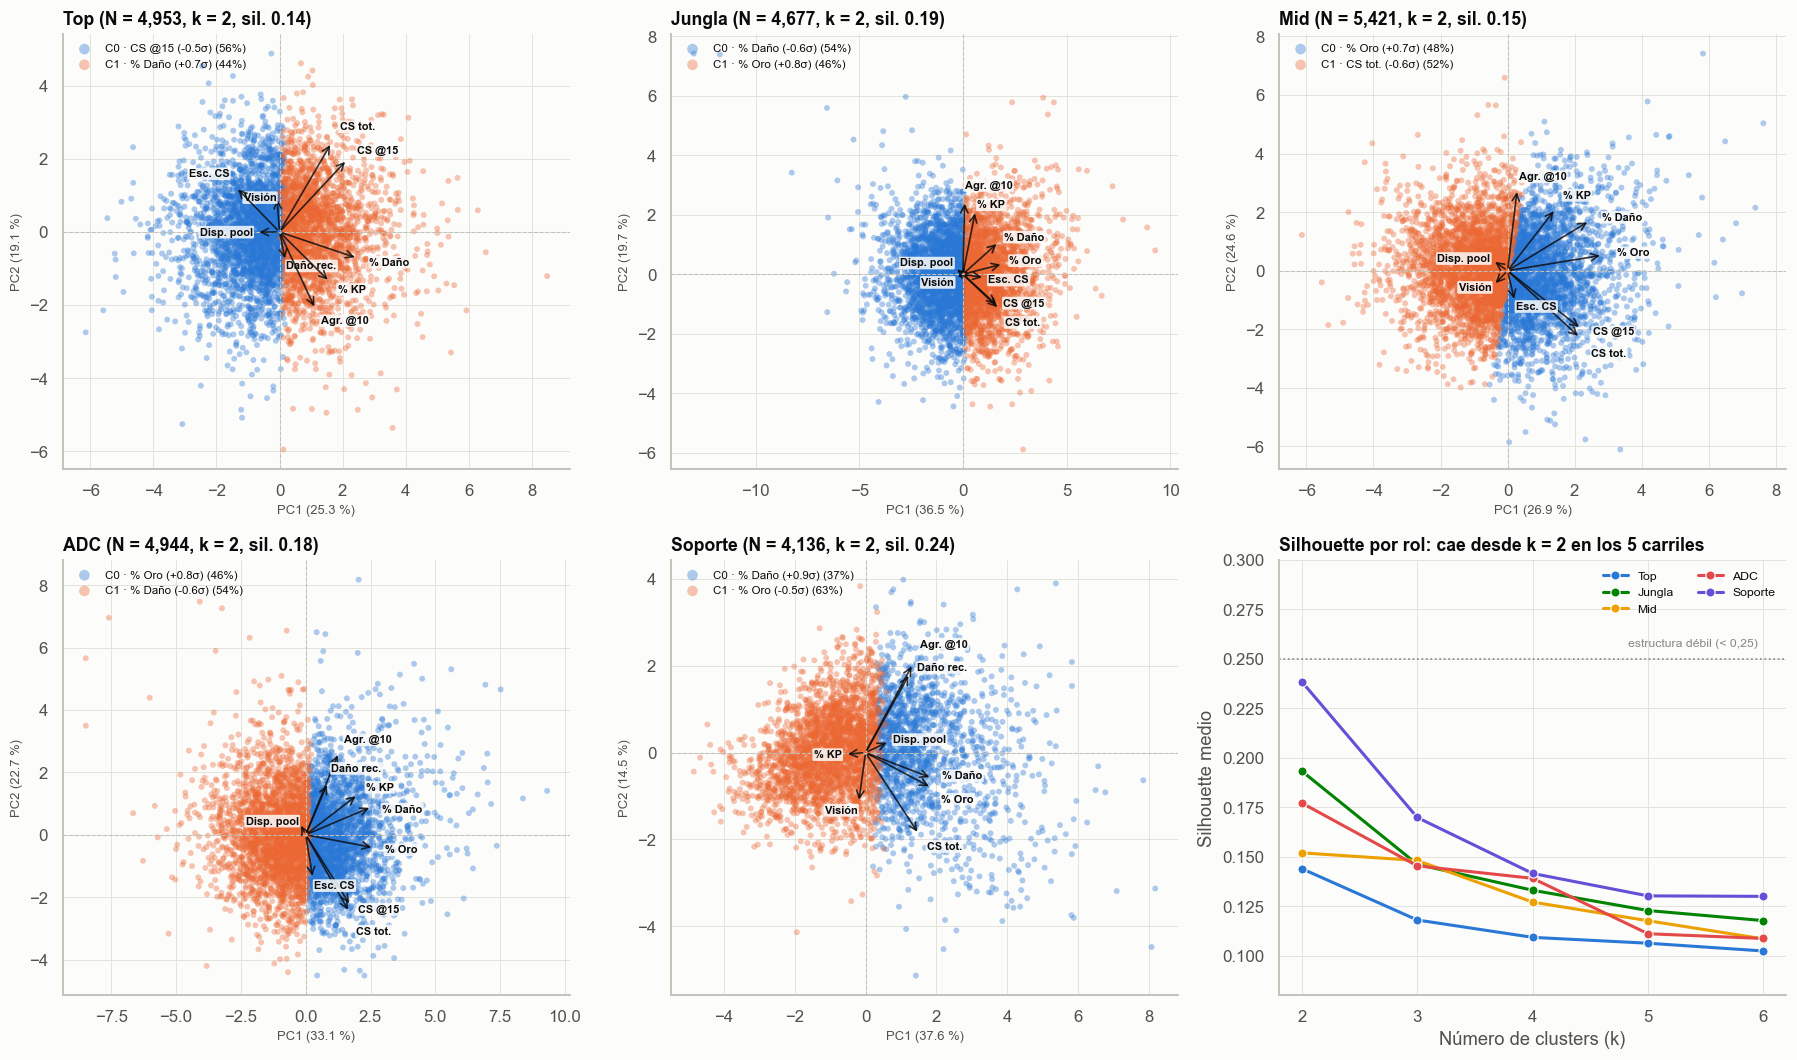

,Jugadores,k óptimo,k = 2,k = 3,k = 4,k = 5,k = 6
Rol,,,,,,,
Top,"4,953",2,0.144,0.118,0.109,0.106,0.102
Jungla,"4,677",2,0.193,0.146,0.133,0.123,0.118
Mid,"5,421",2,0.152,0.148,0.127,0.118,0.109
ADC,"4,944",2,0.177,0.145,0.139,0.111,0.109
Soporte,"4,136",2,0.238,0.170,0.142,0.130,0.130


In [3]:
MIN_LANE_GAMES, MIN_LANE_PCT = 10, 15.0
K_RANGE_ROLE = list(range(2, 7))
target_players = set(df_players.loc[df_players["games_recorded"] >= MIN_GAMES, "player_id"])

query_lane = """
SELECT
    COALESCE(pim.player_id, p.puuid) AS player_id,
    p.individual_position AS lane,
    p.win,
    p.total_damage_taken AS damage_taken,
    (p.total_minions_killed + p.neutral_minions_killed) AS total_cs,
    p.vision_score,
    t.cs_15,
    (t.kills_10 + t.deaths_10 + t.assists_10) AS early_agg_10,
    100.0 * p.total_damage_dealt_to_champions / MAX(1, mt.team_total_damage) AS damage_share_pct,
    100.0 * p.gold_earned / MAX(1, mt.team_total_gold) AS gold_share_pct,
    100.0 * (p.kills + p.assists) / MAX(1, mt.team_total_kills) AS kp_pct
FROM match_participants p
INNER JOIN (
    SELECT match_id, team_id,
           SUM(kills) AS team_total_kills,
           SUM(total_damage_dealt_to_champions) AS team_total_damage,
           SUM(gold_earned) AS team_total_gold
    FROM match_participants
    GROUP BY match_id, team_id
) mt ON p.match_id = mt.match_id AND p.team_id = mt.team_id
LEFT JOIN match_timeline t ON p.match_id = t.match_id AND p.participant_id = t.participant_id
LEFT JOIN player_id_map pim ON pim.puuid = p.puuid
WHERE p.individual_position IN ('TOP', 'JUNGLE', 'MIDDLE', 'BOTTOM', 'UTILITY');
"""

with closing(sqlite3.connect(f"file:{(DATA / 'lol_las.db').resolve()}?mode=ro", uri=True, timeout=60.0)) as conn:
    df_games = pd.read_sql_query(query_lane, conn)

df_games = df_games[df_games["player_id"].isin(target_players)]

df_m = pd.read_csv(DATA / "matchups_1v1.csv",
                   usecols=["blue_player_id", "red_player_id", "lane", "game_duration", "diff_cs_15", "diff_cs_end"])
b_m = df_m[["blue_player_id", "lane", "game_duration", "diff_cs_15", "diff_cs_end"]].rename(
    columns={"blue_player_id": "player_id"})
r_m = df_m[["red_player_id", "lane", "game_duration", "diff_cs_15", "diff_cs_end"]].rename(
    columns={"red_player_id": "player_id"}).assign(diff_cs_15=lambda d: -d["diff_cs_15"],
                                                   diff_cs_end=lambda d: -d["diff_cs_end"])
all_m = pd.concat([b_m, r_m], ignore_index=True)
mins_m = all_m["game_duration"] / 60.0
all_m["cs_scal"] = np.where(mins_m >= 20,
                            (all_m["diff_cs_end"] - all_m["diff_cs_15"]) / (mins_m - 15) - all_m["diff_cs_15"] / 15,
                            np.nan)
matchup_stats = all_m.groupby(["player_id", "lane"])[["cs_scal"]].mean().reset_index()

pls = df_games.groupby(["player_id", "lane"]).agg(
    games_played=("win", "count"),
    avg_damage_taken=("damage_taken", "mean"),
    avg_total_cs=("total_cs", "mean"),
    avg_cs_15=("cs_15", "mean"),
    avg_vision_score=("vision_score", "mean"),
    avg_early_agg_10=("early_agg_10", "mean"),
    avg_damage_share_pct=("damage_share_pct", "mean"),
    avg_gold_share_pct=("gold_share_pct", "mean"),
    avg_kp_pct=("kp_pct", "mean"),
).reset_index()
pls = pls.merge(matchup_stats, on=["player_id", "lane"], how="left").fillna({"cs_scal": 0.0})

sig_b = pd.read_csv(DATA / "player_signatures_B.csv", usecols=["player_id", "lane", "n_games", "pool_dispersion"])
sig_b = sig_b[sig_b["n_games"] >= MIN_LANE_GAMES].drop(columns="n_games")
pls = pls.merge(sig_b, on=["player_id", "lane"], how="left")
pls["pool_dispersion"] = pls.groupby("lane")["pool_dispersion"].transform(lambda s: s.fillna(s.median()))
pls["pool_dispersion"] = pls["pool_dispersion"].fillna(pls["pool_dispersion"].median())
pls["pct_games"] = 100.0 * pls["games_played"] / pls.groupby("player_id")["games_played"].transform("sum")

ROLE_FEATS = {
    "TOP": ["avg_cs_15", "avg_total_cs", "avg_damage_taken", "avg_damage_share_pct", "avg_kp_pct",
            "avg_vision_score", "avg_early_agg_10", "cs_scal", "pool_dispersion"],
    "JUNGLE": ["avg_cs_15", "avg_total_cs", "avg_early_agg_10", "avg_damage_share_pct", "avg_kp_pct",
               "avg_vision_score", "avg_gold_share_pct", "cs_scal", "pool_dispersion"],
    "MIDDLE": ["avg_cs_15", "avg_total_cs", "avg_early_agg_10", "avg_damage_share_pct", "avg_gold_share_pct",
               "avg_kp_pct", "avg_vision_score", "cs_scal", "pool_dispersion"],
    "BOTTOM": ["avg_cs_15", "avg_total_cs", "avg_damage_share_pct", "avg_gold_share_pct", "avg_kp_pct",
               "avg_early_agg_10", "avg_damage_taken", "cs_scal", "pool_dispersion"],
    "UTILITY": ["avg_vision_score", "avg_damage_taken", "avg_early_agg_10", "avg_damage_share_pct", "avg_kp_pct",
                "avg_total_cs", "avg_gold_share_pct", "pool_dispersion"],
}
SHORT_LBL = {
    "avg_cs_15": "CS @15", "avg_total_cs": "CS tot.", "avg_damage_taken": "Daño rec.",
    "avg_damage_share_pct": "% Daño", "avg_gold_share_pct": "% Oro", "avg_kp_pct": "% KP",
    "avg_vision_score": "Visión", "avg_early_agg_10": "Agr. @10", "cs_scal": "Esc. CS",
    "pool_dispersion": "Disp. pool",
}

fig, axes = plt.subplots(2, 3, figsize=(16.5, 9.8))
resumen_roles = []
sil_curves = []

for idx, role in enumerate(CANONICAL_LANES):
    ax = axes[idx // 3, idx % 3]
    sub = pls[(pls["lane"] == role) & (pls["games_played"] >= MIN_LANE_GAMES)
              & (pls["pct_games"] >= MIN_LANE_PCT)].dropna(subset=ROLE_FEATS[role]).reset_index(drop=True)
    feats = ROLE_FEATS[role]
    Xs = StandardScaler().fit_transform(sub[feats].to_numpy())
    pca_r = PCA(n_components=2)
    Xp = pca_r.fit_transform(Xs)
    vr = pca_r.explained_variance_ratio_ * 100

    sils = {k: silhouette_score(Xs, KMeans(n_clusters=k, random_state=SEED, n_init=10).fit_predict(Xs))
            for k in K_RANGE_ROLE}
    k_best = max(sils, key=sils.get)
    for k, v in sils.items():
        sil_curves.append({"Rol": LANE_LABELS[role], "k": k, "Silhouette": v})
    resumen_roles.append({"Rol": LANE_LABELS[role], "Jugadores": len(sub), "k óptimo": k_best,
                          **{f"k = {k}": sils[k] for k in K_RANGE_ROLE}})

    km_r = KMeans(n_clusters=k_best, random_state=SEED, n_init=15)
    lbls = km_r.fit_predict(Xs)
    # Nombre por variable más distintiva (mayor |z| del centroide)
    zc = pd.DataFrame(km_r.cluster_centers_, columns=feats)
    used, c_names = set(), {}
    for c in sorted(range(k_best), key=lambda i: zc.loc[i].abs().max(), reverse=True):
        rk = zc.loc[c].abs().sort_values(ascending=False)
        pick = next((f for f in rk.index if f not in used), rk.index[0])
        used.add(pick)
        c_names[c] = f"C{c} · {SHORT_LBL[pick]} ({zc.loc[c, pick]:+.1f}σ)"

    for c in range(k_best):
        mk = lbls == c
        ax.scatter(Xp[mk, 0], Xp[mk, 1], color=CATEGORICAL[c], alpha=0.38, s=15, edgecolors="none",
                   label=f"{c_names[c]} ({mk.mean():.0%})")
    spread = np.percentile(np.abs(Xp), 95, axis=0).min()
    dibujar_flechas_biplot(ax, pca_r.components_.T, [SHORT_LBL[f] for f in feats], spread, fontsize=7.2, factor=0.95)
    ax.axhline(0, color=BORDER, ls="--", lw=0.7)
    ax.axvline(0, color=BORDER, ls="--", lw=0.7)
    ax.set_xlabel(f"PC1 ({vr[0]:.1f} %)", fontsize=8.5)
    ax.set_ylabel(f"PC2 ({vr[1]:.1f} %)", fontsize=8.5)
    ax.set_title(f"{LANE_LABELS[role]} (N = {len(sub):,}, k = {k_best}, sil. {sils[k_best]:.2f})", loc="left")
    ax.legend(loc="upper left", fontsize=7.5, markerscale=1.8)

# Panel 6: Silhouette según k en todos los roles
ax6 = axes[1, 2]
sc_df = pd.DataFrame(sil_curves)
sns.lineplot(data=sc_df, x="k", y="Silhouette", hue="Rol",
             palette={LANE_LABELS[r]: LANE_COLORS[r] for r in CANONICAL_LANES},
             marker="o", lw=2, ax=ax6)
ax6.axhline(0.25, color=MUTED, ls=":", lw=1.1)
ax6.text(5.95, 0.255, "estructura débil (< 0,25)", ha="right", va="bottom", fontsize=8, color=MUTED)
ax6.set_xticks(K_RANGE_ROLE)
ax6.set_ylim(0.08, 0.30)
ax6.set_xlabel("Número de clusters (k)")
ax6.set_ylabel("Silhouette medio")
ax6.set_title("Silhouette por rol: cae desde k = 2 en los 5 carriles", loc="left")
ax6.legend(title="", fontsize=8, ncol=2, loc="upper right")

plt.tight_layout()
plt.show()

tab_roles = pd.DataFrame(resumen_roles).set_index("Rol")
display(tab_roles.style
        .format({"Jugadores": "{:,}", "k óptimo": "{:d}", **{f"k = {k}": "{:.3f}" for k in K_RANGE_ROLE}})
        .highlight_max(subset=[f"k = {k}" for k in K_RANGE_ROLE], axis=1, props=RESALTE)
        .set_caption("Silhouette de K-Means dentro de cada rol (solo variables de estilo)"))

## 1.3 Independencia del algoritmo: e-means y UMAP + HDBSCAN

¿La falta de grupos depende de K-Means? Se contrastó sobre el espacio ampliado de 15 variables ($N = 14.249$, incluyendo métricas frente al rival) con dos enfoques distintos:
* **e-means** (FAISS 1.16, actualización exponencial por lotes) en tres escenarios: global, centrado por rol y separado por rol (`cluster_emeans.csv`).
* **HDBSCAN sobre UMAP 10D** por rol, que no exige fijar $k$ y marca como ruido los puntos sin densidad local (`umap_vistas.py`, PROJECT_SUMMARY §9.S.58).

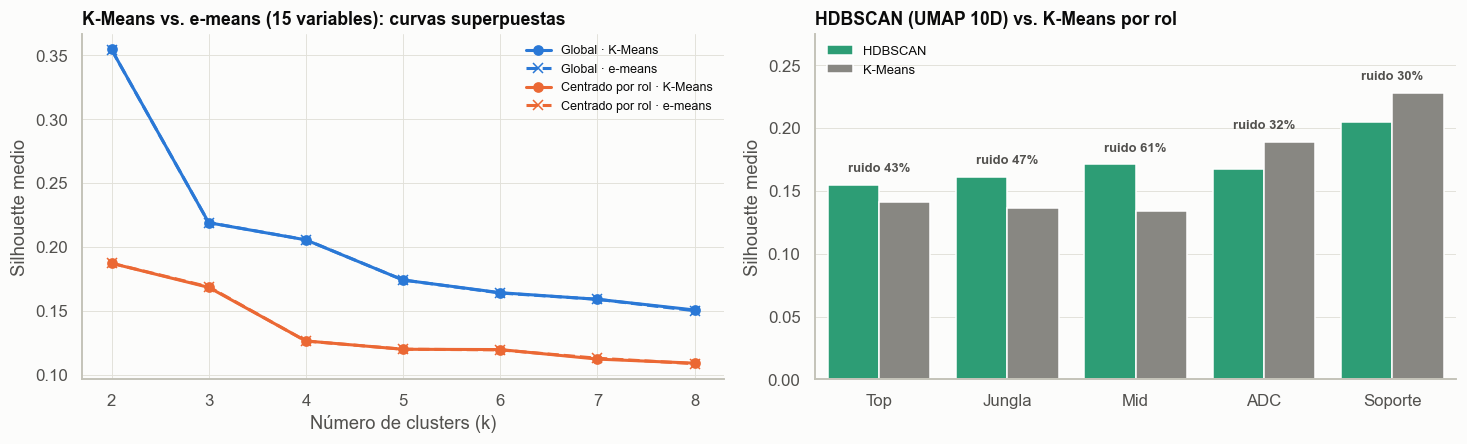

,Sil. K-Means,Sil. e-means,SSE e-means / K-Means,ARI vs. K-Means
Escenario,,,,
Global,0.174,0.174,1.0000,0.987
Centrado por rol,0.120,0.120,1.0000,0.992
Rol: Top,0.141,0.141,1.0001,0.967
Rol: Jungla,0.136,0.136,1.0001,0.972
Rol: Mid,0.134,0.134,1.0001,0.989
Rol: ADC,0.145,0.146,1.0001,0.982
Rol: Soporte,0.152,0.152,1.0001,0.985


,Jugadores,Grupos,% Ruido,ARI vs K-Means,Sil. HDBSCAN,Sil. K-Means
Rol,,,,,,
Top,"2,520",5,43%,0.50,0.155,0.141
Jungla,"2,856",5,47%,0.47,0.161,0.136
Mid,"3,323",5,61%,0.55,0.171,0.134
ADC,"2,900",3,32%,0.32,0.167,0.189
Soporte,"2,650",3,30%,0.45,0.205,0.228


In [4]:
ce = pd.read_csv(ANALYSIS / "cluster_emeans.csv")
umap_res = pd.DataFrame([
    {"Rol": "Top", "Jugadores": 2520, "Grupos": 5, "% Ruido": 0.43, "ARI vs K-Means": 0.50,
     "Sil. HDBSCAN": 0.155, "Sil. K-Means": 0.141},
    {"Rol": "Jungla", "Jugadores": 2856, "Grupos": 5, "% Ruido": 0.47, "ARI vs K-Means": 0.47,
     "Sil. HDBSCAN": 0.161, "Sil. K-Means": 0.136},
    {"Rol": "Mid", "Jugadores": 3323, "Grupos": 5, "% Ruido": 0.61, "ARI vs K-Means": 0.55,
     "Sil. HDBSCAN": 0.171, "Sil. K-Means": 0.134},
    {"Rol": "ADC", "Jugadores": 2900, "Grupos": 3, "% Ruido": 0.32, "ARI vs K-Means": 0.32,
     "Sil. HDBSCAN": 0.167, "Sil. K-Means": 0.189},
    {"Rol": "Soporte", "Jugadores": 2650, "Grupos": 3, "% Ruido": 0.30, "ARI vs K-Means": 0.45,
     "Sil. HDBSCAN": 0.205, "Sil. K-Means": 0.228},
])

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.2))

# Izquierda: K-Means vs e-means (global y centrado por rol)
d_em = ce[ce["escenario"].isin(["global", "centrado_rol"]) & ce["metodo"].isin(["kmeans", "emeans"])].copy()
for (esc, lbl_e, col) in [("global", "Global", CATEGORICAL[0]), ("centrado_rol", "Centrado por rol", CATEGORICAL[1])]:
    for met, lbl_m, ls, mk in [("kmeans", "K-Means", "-", "o"), ("emeans", "e-means", "--", "x")]:
        s = d_em[(d_em["escenario"] == esc) & (d_em["metodo"] == met)].sort_values("k")
        axes[0].plot(s["k"], s["silhouette"], color=col, ls=ls, marker=mk, ms=6, lw=2,
                     label=f"{lbl_e} · {lbl_m}")
axes[0].set_xlabel("Número de clusters (k)")
axes[0].set_ylabel("Silhouette medio")
axes[0].set_title("K-Means vs. e-means (15 variables): curvas superpuestas", loc="left")
axes[0].legend(fontsize=8.2, loc="upper right")

# Derecha: HDBSCAN (UMAP 10D) vs K-Means por rol + % de ruido anotado
u_long = umap_res.melt(id_vars=["Rol", "% Ruido"], value_vars=["Sil. HDBSCAN", "Sil. K-Means"],
                       var_name="Método", value_name="Silhouette")
u_long["Método"] = u_long["Método"].str.replace("Sil. ", "", regex=False)
sns.barplot(data=u_long, x="Rol", y="Silhouette", hue="Método", palette=[CATEGORICAL[2], MUTED], ax=axes[1])
for i, r in umap_res.iterrows():
    ymax = max(r["Sil. HDBSCAN"], r["Sil. K-Means"])
    axes[1].text(i, ymax + 0.008, f"ruido {r['% Ruido']:.0%}", ha="center", va="bottom",
                 fontsize=8.5, fontweight="bold", color=INK_2)
axes[1].set_ylim(0, 0.275)
axes[1].set_xlabel("")
axes[1].set_ylabel("Silhouette medio")
axes[1].set_title("HDBSCAN (UMAP 10D) vs. K-Means por rol", loc="left")
axes[1].grid(axis="x", visible=False)
axes[1].legend(fontsize=8.5, title="", loc="upper left")

plt.tight_layout()
plt.show()

# Tabla compacta: K-Means vs e-means (k = 5)
k5 = ce[(ce["k"] == 5) & ce["metodo"].isin(["kmeans", "emeans"])].pivot(
    index="escenario", columns="metodo", values=["silhouette", "sse_mejor", "ari_vs_kmeans"])
esc_lbl = {"global": "Global", "centrado_rol": "Centrado por rol",
           **{f"rol_{r}": f"Rol: {LANE_LABELS[r]}" for r in CANONICAL_LANES}}
tab_em = pd.DataFrame({
    "Sil. K-Means": k5[("silhouette", "kmeans")],
    "Sil. e-means": k5[("silhouette", "emeans")],
    "SSE e-means / K-Means": k5[("sse_mejor", "emeans")] / k5[("sse_mejor", "kmeans")],
    "ARI vs. K-Means": k5[("ari_vs_kmeans", "emeans")],
}).reindex(list(esc_lbl)).rename(index=esc_lbl).rename_axis("Escenario")
display(tab_em.style.format({"Sil. K-Means": "{:.3f}", "Sil. e-means": "{:.3f}",
                             "SSE e-means / K-Means": "{:.4f}", "ARI vs. K-Means": "{:.3f}"})
        .set_caption("K-Means contra e-means en k = 5 (15 variables, N = 14.249)"))

display(umap_res.set_index("Rol").style
        .format({"Jugadores": "{:,}", "% Ruido": "{:.0%}", "ARI vs K-Means": "{:.2f}",
                 "Sil. HDBSCAN": "{:.3f}", "Sil. K-Means": "{:.3f}"})
        .set_caption("HDBSCAN sobre UMAP 10D dentro de cada rol (PROJECT_SUMMARY §9.S.58)"))

**Lectura de la Sección 1.**
* **No hay tipos discretos de jugador.** El clustering global solo recupera la división *Soporte vs. resto* ($k = 2$, silhouette $0{,}483$). Al controlar por rol, el silhouette cae a $0{,}14\text{–}0{,}24$ y decrece de forma monótona desde $k = 2$ en los cinco carriles.
* **El hallazgo no depende del algoritmo.** e-means replica la partición de K-Means (SSE a $< 0{,}1\ \%$, $\text{ARI} \ge 0{,}97$); HDBSCAN sobre UMAP 10D descarta entre **30 % y 61 %** de los jugadores como ruido y coincide solo parcialmente con K-Means ($\text{ARI}\ 0{,}32\text{–}0{,}55$).
* **El estilo es un continuo** (en 15D el eje global principal es la *habilidad*, de 46 % a 58 % de winrate). Cualquier partición fija es descriptiva y no corresponde a grupos naturales.

# 2. ¿Cada persona tiene un estilo propio? (Nivel 1)

## 2.1 Representación y cobertura del train

Que no existan *islas* no impide que cada persona ocupe siempre la misma región del continuo. Representamos cada partida con **23 estadísticas de juego** (tasas por minuto y estado @10/@15), residualizadas dentro del grupo *(campeón, línea, resultado)*:

$$z = \frac{x - \mu_{c,l,w}}{\sigma_{c,l,w}}, \qquad n_{c,l,w} \ge 30$$

Condicionar por campeón y línea remueve el rol y el personaje; condicionar por resultado $w$ evita confundir estilo con "ganar más". Todo se calcula sobre el **train** Master+ de LAS (`data/splits/train/full_dataset.csv`).

Indicador,Valor
"Partidas únicas (train Master+, LAS)","189,076"
Jugadores Master+,"8,997"
Filas jugador-partida (crudas),"1,244,647"
Filas con algún faltante de timeline (@10/@15),1.03%
"Descartadas por grupo (campeón, línea, resultado) < 30",0.52%
Filas residualizadas útiles,"1,225,439 (98.5%)"
Partidas por jugador (mediana / media / máx.),"109 / 138.3 / 1,342"
Jugadores elegibles para k = 20 e ICC (≥ 40 partidas),"8,683 (96.5%; aportan 99.2% de las filas)"


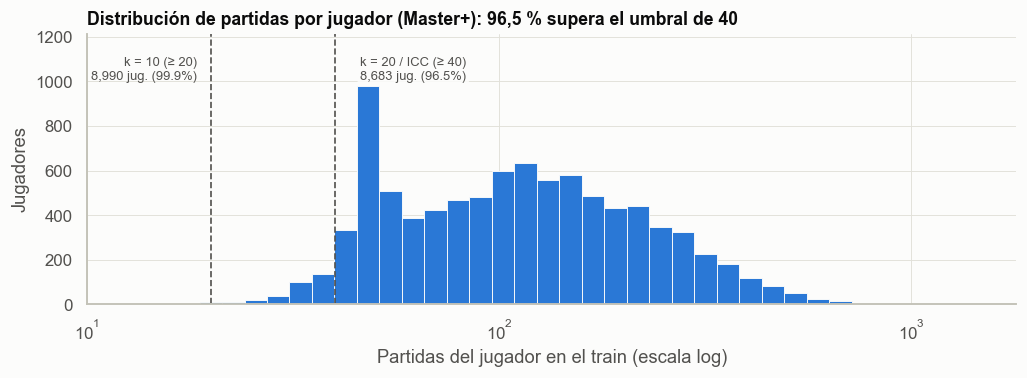

In [5]:
raw = load_train(TRAIN)
resid = residualize(raw)

n_raw = raw.groupby("player_id").size()
n_res = resid.groupby("player_id").size()
pct_na = raw[STYLE_FEATURES].isna().any(axis=1).mean()
d0_len = int((~raw[STYLE_FEATURES].isna().any(axis=1)).sum())
pct_small = 1.0 - len(resid) / d0_len

resumen_cov = pd.DataFrame([
    {"Indicador": "Partidas únicas (train Master+, LAS)", "Valor": f"{raw['match_id'].nunique():,}"},
    {"Indicador": "Jugadores Master+", "Valor": f"{raw['player_id'].nunique():,}"},
    {"Indicador": "Filas jugador-partida (crudas)", "Valor": f"{len(raw):,}"},
    {"Indicador": "Filas con algún faltante de timeline (@10/@15)", "Valor": f"{pct_na:.2%}"},
    {"Indicador": "Descartadas por grupo (campeón, línea, resultado) < 30", "Valor": f"{pct_small:.2%}"},
    {"Indicador": "Filas residualizadas útiles", "Valor": f"{len(resid):,} ({len(resid) / len(raw):.1%})"},
    {"Indicador": "Partidas por jugador (mediana / media / máx.)",
     "Valor": f"{n_raw.median():.0f} / {n_raw.mean():.1f} / {n_raw.max():,}"},
    {"Indicador": "Jugadores elegibles para k = 20 e ICC (≥ 40 partidas)",
     "Valor": f"{(n_raw >= 40).sum():,} ({(n_raw >= 40).mean():.1%}; aportan {n_raw[n_raw >= 40].sum() / len(raw):.1%} de las filas)"},
])
display(resumen_cov.style.hide(axis="index").set_caption("Cobertura y calidad del train Master+"))

fig, ax = plt.subplots(figsize=(9.5, 3.6))
bins = np.logspace(np.log10(10), np.log10(n_raw.max() + 1), 40)
ax.hist(n_raw, bins=bins, color=CATEGORICAL[0], edgecolor="#fcfcfb", lw=0.6)
ax.set_xscale("log")
ax.set_xlim(10, 1800)
ymax = ax.get_ylim()[1]
ax.set_ylim(0, ymax * 1.18)
ax.axvline(20, color=INK_2, ls="--", lw=1.1)
ax.text(18.5, ymax * 1.08, f"k = 10 (≥ 20)\n{(n_raw >= 20).sum():,} jug. ({(n_raw >= 20).mean():.1%})",
        color=INK_2, fontsize=8.5, ha="right", va="top")
ax.axvline(40, color=INK_2, ls="--", lw=1.1)
ax.text(46, ymax * 1.08, f"k = 20 / ICC (≥ 40)\n{(n_raw >= 40).sum():,} jug. ({(n_raw >= 40).mean():.1%})",
        color=INK_2, fontsize=8.5, ha="left", va="top",
        bbox=dict(boxstyle="round,pad=0.2", facecolor="#fcfcfb", edgecolor="none", alpha=0.85))
ax.set_xlabel("Partidas del jugador en el train (escala log)")
ax.set_ylabel("Jugadores")
ax.set_title("Distribución de partidas por jugador (Master+): 96,5 % supera el umbral de 40", loc="left")
plt.tight_layout()
plt.show()

## 2.2 ¿De quién es cada estadística? Descomposición de varianza e ICC

Sobre las mismas filas que sobreviven a la residualización, descomponemos la varianza total de cada estadística en $R^2$ incrementales por **línea**, **campeón** y **resultado**; dentro del residuo remanente, la correlación intraclase ($\text{ICC}(1)$, con corrección por tamaño finito en jugadores con $\ge 40$ partidas) mide qué fracción pertenece a la **persona**:

$$\text{ICC} = \frac{\sigma^2_b - \sigma^2_w/\bar n}{\sigma^2_b - \sigma^2_w/\bar n + \sigma^2_w}$$

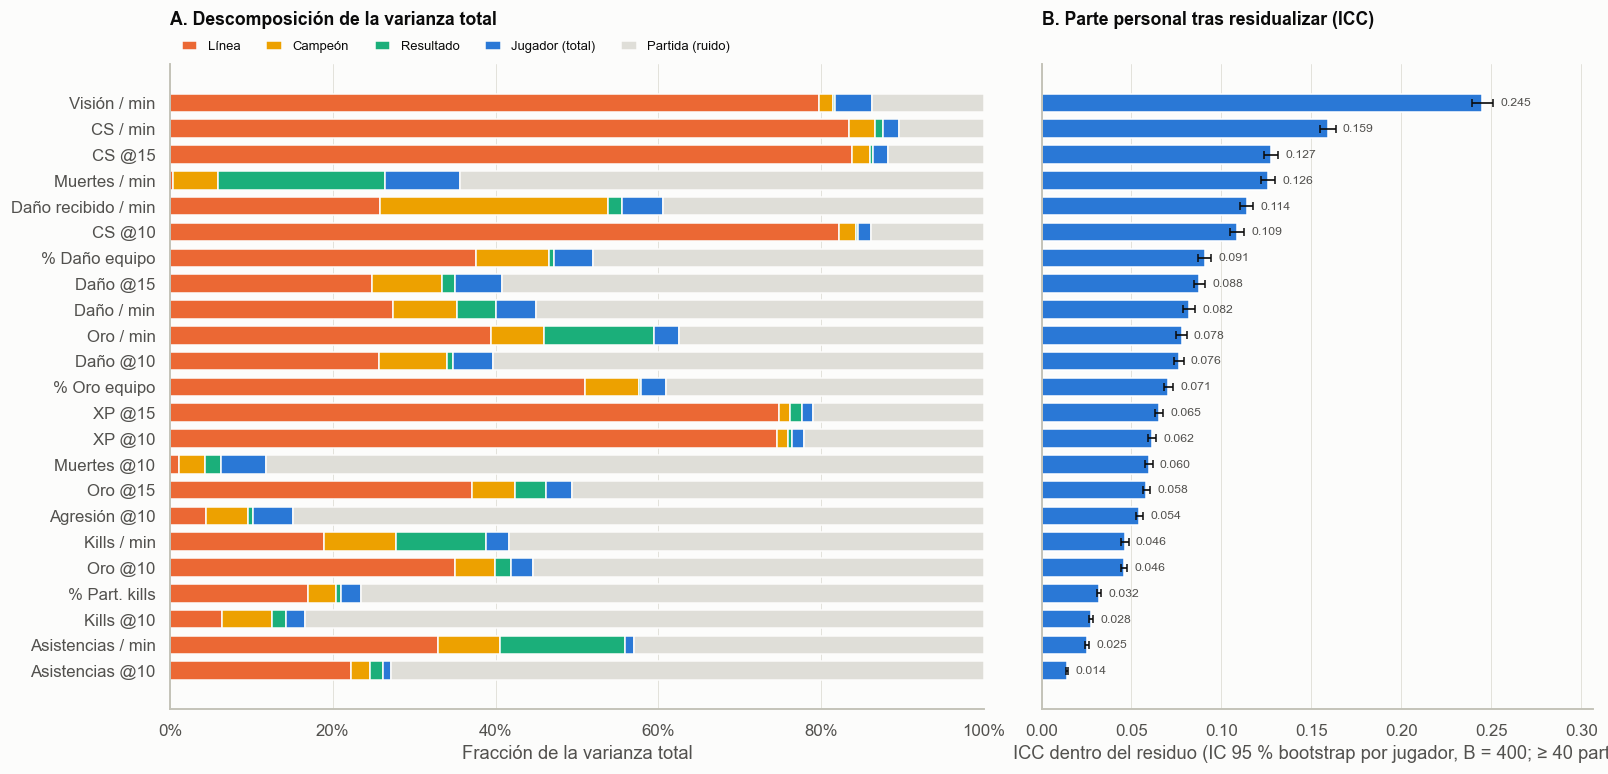

,Línea,Campeón,Resultado,Jugador (total),Partida (ruido),ICC (residuo)
Visión / min,79.8%,1.7%,0.2%,4.5%,13.8%,0.245
CS / min,83.4%,3.3%,1.0%,2.0%,10.4%,0.159
CS @15,83.8%,2.2%,0.4%,1.7%,11.8%,0.127
Muertes / min,0.4%,5.5%,20.6%,9.3%,64.3%,0.126
Daño recibido / min,25.7%,28.0%,1.8%,5.1%,39.4%,0.114
CS @10,82.2%,2.1%,0.2%,1.7%,13.8%,0.109
% Daño equipo,37.6%,8.9%,0.7%,4.8%,48.0%,0.091
Daño @15,24.8%,8.7%,1.6%,5.7%,59.2%,0.088


In [6]:
base = raw.loc[resid.index]


def r2_grupo(cols):
    dev = base[STYLE_FEATURES] - base.groupby(cols)[STYLE_FEATURES].transform("mean")
    return 1.0 - dev.var() / base[STYLE_FEATURES].var()


r2_l = r2_grupo(["lane"])
r2_cl = r2_grupo(["champion_name", "lane"])
r2_clw = r2_grupo(["champion_name", "lane", "win"])
icc_23 = player_variance_share(resid, min_games=40)

# IC 95 % bootstrap por jugador (B = 400) para el ICC(1) de las 23 estadísticas
_n_p = resid.groupby("player_id").size()
_d40 = resid[resid["player_id"].isin(_n_p[_n_p >= 40].index)]
_g40 = _d40.groupby("player_id")[STYLE_FEATURES]
_mu_p = _g40.mean().to_numpy(float)
_var_p = _g40.var().to_numpy(float)
_cnt_p = _g40.size().to_numpy(float)
_rng_icc = np.random.default_rng(12)
_B_ICC = 400
_icc_b = np.empty((_B_ICC, len(STYLE_FEATURES)), dtype=float)
for _b in range(_B_ICC):
    _idx = _rng_icc.integers(0, len(_cnt_p), size=len(_cnt_p))
    _w = _var_p[_idx].mean(axis=0)
    _bt = _mu_p[_idx].var(axis=0, ddof=1) - _w / _cnt_p[_idx].mean()
    _icc_b[_b] = _bt / (_bt + _w)
icc_lo = pd.Series(np.percentile(_icc_b, 2.5, axis=0), index=STYLE_FEATURES)
icc_hi = pd.Series(np.percentile(_icc_b, 97.5, axis=0), index=STYLE_FEATURES)

rep = pd.DataFrame({
    "Línea": r2_l,
    "Campeón": r2_cl - r2_l,
    "Resultado": r2_clw - r2_cl,
    "Residuo": 1.0 - r2_clw,
})
rep["Jugador (total)"] = rep["Residuo"] * icc_23.reindex(rep.index)
rep["Partida (ruido)"] = rep["Residuo"] - rep["Jugador (total)"]
rep["ICC (residuo)"] = icc_23.reindex(rep.index)
rep = rep.sort_values("ICC (residuo)", ascending=True)
_lo_ord = icc_lo.reindex(rep.index).to_numpy()
_hi_ord = icc_hi.reindex(rep.index).to_numpy()

partes = ["Línea", "Campeón", "Resultado", "Jugador (total)", "Partida (ruido)"]
col_partes = [CATEGORICAL[1], CATEGORICAL[3], CATEGORICAL[2], CATEGORICAL[0], "#dfded8"]
etiquetas_y = [FEAT_LABELS[f] for f in rep.index]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14.8, 7.2), sharey=True, gridspec_kw={"width_ratios": [1.55, 1.05]})

izq = np.zeros(len(rep))
for parte, col in zip(partes, col_partes):
    ax1.barh(etiquetas_y, rep[parte], left=izq, color=col, height=0.72, edgecolor="#fcfcfb", lw=1.0, label=parte)
    izq += rep[parte].to_numpy()
ax1.set_xlim(0, 1)
ax1.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax1.set_xlabel("Fracción de la varianza total")
ax1.set_title("A. Descomposición de la varianza total", loc="left", pad=26)
ax1.legend(ncol=5, loc="lower left", bbox_to_anchor=(0.0, 1.0), fontsize=8.5, handlelength=1.2)
ax1.grid(axis="y", visible=False)

_y_icc = np.arange(len(rep))
_v_icc = rep["ICC (residuo)"].to_numpy()
ax2.barh(_y_icc, _v_icc, color=CATEGORICAL[0], height=0.72)
ax2.errorbar(_v_icc, _y_icc,
             xerr=[np.maximum(0.0, _v_icc - _lo_ord), np.maximum(0.0, _hi_ord - _v_icc)],
             fmt="none", ecolor=INK, elinewidth=1.1, capsize=2.6, zorder=5)
for yi, (v, hi_v) in enumerate(zip(_v_icc, _hi_ord)):
    ax2.text(hi_v + 0.004, yi, f"{v:.3f}", va="center", fontsize=8, color=INK_2)
ax2.set_yticks(_y_icc, etiquetas_y)
ax2.set_xlim(0, float(np.max(_hi_ord)) * 1.22)
ax2.set_xlabel(f"ICC dentro del residuo (IC 95 % bootstrap por jugador, B = {_B_ICC}; ≥ 40 part.)")
ax2.set_title("B. Parte personal tras residualizar (ICC)", loc="left", pad=26)
ax2.grid(axis="y", visible=False)

plt.tight_layout()
plt.show()

top8 = rep.sort_values("ICC (residuo)", ascending=False).head(8)[
    ["Línea", "Campeón", "Resultado", "Jugador (total)", "Partida (ruido)", "ICC (residuo)"]
].rename(index=FEAT_LABELS)
display(top8.style
        .format({"Línea": "{:.1%}", "Campeón": "{:.1%}", "Resultado": "{:.1%}",
                 "Jugador (total)": "{:.1%}", "Partida (ruido)": "{:.1%}", "ICC (residuo)": "{:.3f}"})
        .highlight_max(subset=["Jugador (total)", "ICC (residuo)"], props=RESALTE)
        .set_caption("Top 8 estadísticas más personales (ordenadas por ICC en el residuo)"))

**Lectura.**
* **La línea explica 75–84 %** de farm, XP y visión; el campeón pesa en daño recibido (28 %) y el resultado en muertes (21 %), asistencias y oro.
* **Lo más personal son hábitos individuales:** visión ($\text{ICC}\ 0{,}245$), farm (`CS / min` $0{,}159$, `CS @15` $0{,}127$), muertes ($0{,}126$) y daño recibido ($0{,}114$). Lo menos personal depende del equipo (asistencias, participación en kills).
* **ICC vs. peso absoluto:** la visión lidera el ICC ($0{,}245$), pero es 4,5 % de la varianza bruta (80 % es rol); en absoluto lidera `Muertes / min` (9,3 %). Para la huella manda el ICC porque cada residuo se estandariza a $\sigma = 1$.

## 2.3 Estructura interna y control de elo y rol

Antes de evaluar reidentificación verificamos dos propiedades del perfil residualizado (jugadores con $\ge 40$ partidas): cuántas dimensiones independientes contienen las 23 variables y si el tier o la línea principal se filtran en los residuos.

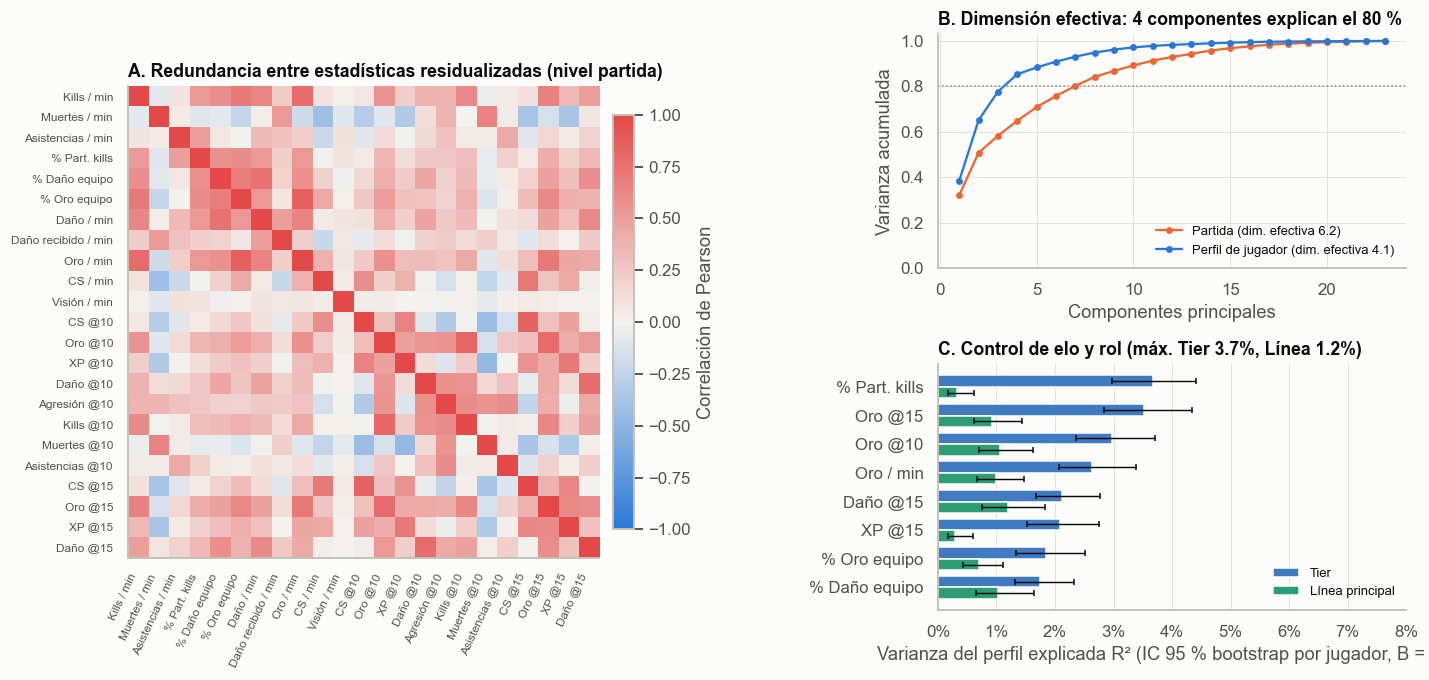

In [7]:
maduros = n_res[n_res >= 40].index
perfil = resid[resid["player_id"].isin(maduros)].groupby("player_id")[STYLE_FEATURES].mean()
info = player_info(resid).loc[maduros]

corr = resid[STYLE_FEATURES].corr()


def var_exp(X):
    Xc = X - X.mean(axis=0)
    s = np.linalg.svd(Xc, compute_uv=False) ** 2
    return s / s.sum()


ev_part = var_exp(resid[STYLE_FEATURES].sample(200_000, random_state=0).to_numpy())
ev_jug = var_exp(perfil.to_numpy())
pr_part, pr_jug = 1.0 / np.sum(ev_part ** 2), 1.0 / np.sum(ev_jug ** 2)


def r2_perfil(clave):
    g = perfil.join(info).groupby(clave)[STYLE_FEATURES].transform("mean")
    return 1.0 - (perfil - g).var() / perfil.var()


r2_ctrl = pd.DataFrame({
    "Tier": r2_perfil("player_tier"),
    "Línea principal": r2_perfil("main_lane"),
}).sort_values("Tier", ascending=False)

fig = plt.figure(figsize=(15.0, 6.8))
gs = GridSpec(2, 2, width_ratios=[1.22, 1.0], height_ratios=[1.0, 1.05], figure=fig, wspace=0.46, hspace=0.40)

# Izquierda: matriz de correlación de las 23 estadísticas residualizadas
ax_c = fig.add_subplot(gs[:, 0])
lbls_23 = [FEAT_LABELS[f] for f in STYLE_FEATURES]
im = ax_c.imshow(corr.to_numpy(), cmap=DIVERGENTE, vmin=-1, vmax=1)
ax_c.set_xticks(range(len(STYLE_FEATURES)), lbls_23, rotation=65, ha="right", fontsize=7.8)
ax_c.set_yticks(range(len(STYLE_FEATURES)), lbls_23, fontsize=7.8)
ax_c.grid(False)
fig.colorbar(im, ax=ax_c, shrink=0.72, pad=0.025, label="Correlación de Pearson")
ax_c.set_title("A. Redundancia entre estadísticas residualizadas (nivel partida)", loc="left")

# Arriba derecha: varianza acumulada y dimensión efectiva
ax_v = fig.add_subplot(gs[0, 1])
xs = np.arange(1, len(STYLE_FEATURES) + 1)
ax_v.plot(xs, np.cumsum(ev_part), color=CATEGORICAL[1], marker="o", ms=3.5,
          label=f"Partida (dim. efectiva {pr_part:.1f})")
ax_v.plot(xs, np.cumsum(ev_jug), color=CATEGORICAL[0], marker="o", ms=3.5,
          label=f"Perfil de jugador (dim. efectiva {pr_jug:.1f})")
ax_v.axhline(0.80, color=MUTED, ls=":", lw=1.0)
ax_v.set_ylim(0, 1.03)
ax_v.set_xlabel("Componentes principales")
ax_v.set_ylabel("Varianza acumulada")
ax_v.set_title("B. Dimensión efectiva: 4 componentes explican el 80 %", loc="left")
ax_v.legend(fontsize=8.5, loc="lower right")

# Abajo derecha: R² residual del tier y de la línea principal (top 8 por tier, IC 95 % bootstrap por jugador)
ax_r = fig.add_subplot(gs[1, 1])
top_f = list(r2_ctrl.head(8).index)
_rng_r2 = np.random.default_rng(15)
_B_R2 = 400
_X_top = perfil[top_f].to_numpy(float)
_ic_r2 = {}
for _fac, _col in (("Tier", "player_tier"), ("Línea principal", "main_lane")):
    _codes = pd.Categorical(info[_col]).codes
    _ok = _codes >= 0
    _Xo, _co = _X_top[_ok], _codes[_ok]
    _nc = int(_co.max()) + 1
    _draws = np.empty((_B_R2, len(top_f)), dtype=float)
    for _b in range(_B_R2):
        _idx = _rng_r2.integers(0, len(_co), size=len(_co))
        _Xb, _cb = _Xo[_idx], _co[_idx]
        _cnt = np.bincount(_cb, minlength=_nc).astype(float)
        _gm = np.zeros((_nc, len(top_f)), dtype=float)
        np.add.at(_gm, _cb, _Xb)
        _gm /= np.maximum(_cnt[:, None], 1.0)
        _dev = _Xb - _gm[_cb]
        _draws[_b] = 1.0 - _dev.var(axis=0, ddof=1) / _Xb.var(axis=0, ddof=1)
    _ic_r2[_fac] = (np.percentile(_draws, 2.5, axis=0), np.percentile(_draws, 97.5, axis=0))

top_ctrl = r2_ctrl.head(8).rename(index=FEAT_LABELS).reset_index().rename(columns={"index": "Variable"})
ctrl_long = top_ctrl.melt(id_vars="Variable", var_name="Factor", value_name="R2")
sns.barplot(data=ctrl_long, y="Variable", x="R2", hue="Factor",
            palette=[CATEGORICAL[0], CATEGORICAL[2]], ax=ax_r)
for cont, _fac in zip(ax_r.containers, ("Tier", "Línea principal")):
    _vals = r2_ctrl.head(8)[_fac].to_numpy(float)
    _lo_f, _hi_f = _ic_r2[_fac]
    _ys_f = np.array([b.get_y() + b.get_height() / 2 for b in cont])
    ax_r.errorbar(_vals, _ys_f,
                  xerr=[np.maximum(0.0, _vals - _lo_f), np.maximum(0.0, _hi_f - _vals)],
                  fmt="none", ecolor=INK, elinewidth=0.95, capsize=2.0, zorder=5)
ax_r.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax_r.set_xlim(0, max(0.08, float(max(_ic_r2["Tier"][1].max(), _ic_r2["Línea principal"][1].max())) * 1.15))
ax_r.set_ylabel("")
ax_r.set_xlabel(f"Varianza del perfil explicada R² (IC 95 % bootstrap por jugador, B = {_B_R2})")
ax_r.set_title(f"C. Control de elo y rol (máx. Tier {r2_ctrl['Tier'].max():.1%}, Línea {r2_ctrl['Línea principal'].max():.1%})",
               loc="left")
ax_r.grid(axis="y", visible=False)
ax_r.legend(title="", fontsize=8.5, loc="lower right")

plt.show()

**Lectura.**
* **Alta redundancia:** las 23 variables se condensan en **4,1 dimensiones efectivas** a nivel perfil (bloques correlacionados con $r > 0{,}80$: oro, farm, XP y daño). La distancia euclídea sin pesos cuenta esos bloques repetidas veces y la visión una sola: eso motiva las métricas pesadas de la Sección 3.
* **Residualización limpia:** sobre los perfiles maduros, el tier explica como máximo **3,7 %** de la varianza y la línea principal **1,2 %**. La huella no es un proxy de elo ni de rol.

## 2.4 Nivel 1: reidentificación contra baselines y deriva temporal

Para cada jugador comparamos dos mitades disjuntas de $k$ partidas ($A$ y $B$). El **AUC por fila** es la fracción de otros jugadores cuya mitad $B$ queda más lejos que la propia ($0{,}5$ = azar). La prueba exigente combina **campeones distintos** entre $A$ y $B$ con **rivales difíciles** (mismo tier y línea principal), contrastando la `huella` contra cuatro baselines: `crudo` (sin descontar campeón), `embedding` (embeddings de campeones), `pool` (frecuencia de campeones) y `elo_linea` (tier + reparto de líneas).

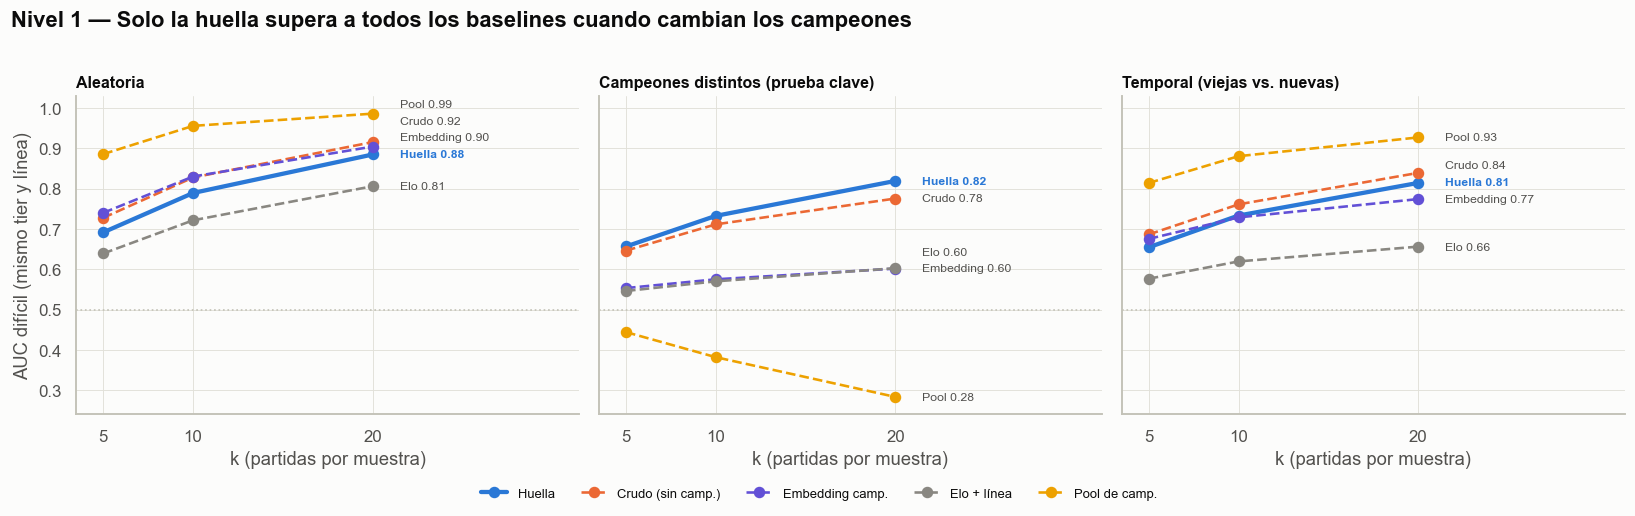

,Camp. dist. k=5 (dif.),Camp. dist. k=10 (dif.),Camp. dist. k=20 (dif.),Camp. dist. k=20 (global),Aleatoria k=20 (dif.),Temporal k=20 (dif.)
Representación,,,,,,
Huella,0.656,0.732,0.819,0.823,0.885,0.814
Crudo (sin camp.),0.646,0.711,0.775,0.784,0.915,0.839
Embedding camp.,0.553,0.575,0.602,0.791,0.904,0.774
Elo + línea,0.546,0.570,0.603,0.919,0.806,0.656
Pool de camp.,0.444,0.382,0.283,0.347,0.986,0.927


In [8]:
n1_raw = json.loads((ANALYSIS / "huella_nivel1.json").read_text(encoding="utf-8"))
res_n1 = pd.DataFrame(n1_raw["resultados"])
agg_n1 = res_n1.groupby(["muestra", "representacion", "k"])[["auc", "auc_dificil", "top1"]].mean().reset_index()

REP_ORDER = ["huella", "crudo", "embedding", "elo_linea", "pool"]
REP_NAMES = {"huella": "Huella", "crudo": "Crudo (sin camp.)", "embedding": "Embedding camp.",
             "elo_linea": "Elo + línea", "pool": "Pool de camp."}
REP_COL = {"huella": CATEGORICAL[0], "crudo": CATEGORICAL[1], "embedding": CATEGORICAL[6],
           "elo_linea": MUTED, "pool": CATEGORICAL[3]}
MUESTRA_LBL = {"aleatoria": "Aleatoria", "campeones_distintos": "Campeones distintos (prueba clave)",
               "temporal": "Temporal (viejas vs. nuevas)"}

fig, axes = plt.subplots(1, 3, figsize=(15, 4.3), sharey=True)
for ax, m in zip(axes, ["aleatoria", "campeones_distintos", "temporal"]):
    finales = {}
    for r in REP_ORDER:
        s = agg_n1[(agg_n1["muestra"] == m) & (agg_n1["representacion"] == r)].sort_values("k")
        ax.plot(s["k"], s["auc_dificil"], color=REP_COL[r], marker="o", ms=6.5,
                lw=2.8 if r == "huella" else 1.7, ls="-" if r == "huella" else "--",
                label=REP_NAMES[r])
        finales[r] = float(s["auc_dificil"].iat[-1])
    y_prev = -np.inf
    for r, v in sorted(finales.items(), key=lambda kv: kv[1]):
        yy = max(v, y_prev + 0.042)
        ax.annotate(f"{REP_NAMES[r].split()[0]} {v:.2f}", (20, v), xytext=(21.5, yy),
                    va="center", fontsize=8, fontweight="bold" if r == "huella" else "normal",
                    color=REP_COL[r] if r == "huella" else INK_2)
        y_prev = yy
    ax.axhline(0.5, color=BORDER, ls=":", lw=1.1)
    ax.set_xticks([5, 10, 20])
    ax.set_xlim(3.5, 31.5)
    ax.set_ylim(0.24, 1.03)
    ax.set_xlabel("k (partidas por muestra)")
    ax.set_title(MUESTRA_LBL[m], loc="left", fontsize=10.5)
axes[0].set_ylabel("AUC difícil (mismo tier y línea)")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", bbox_to_anchor=(0.5, -0.05), ncol=5, fontsize=8.5)
fig.suptitle("Nivel 1 — Solo la huella supera a todos los baselines cuando cambian los campeones",
             x=0.01, ha="left", fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()

# Tabla estilizada: foco en campeones distintos (global y difícil) + referencia aleatoria/temporal en k=20
cd_n1 = agg_n1[agg_n1["muestra"] == "campeones_distintos"]
p_dif = cd_n1.pivot(index="representacion", columns="k", values="auc_dificil").reindex(REP_ORDER)
p_glb = cd_n1.pivot(index="representacion", columns="k", values="auc").reindex(REP_ORDER)
p_ale = agg_n1[(agg_n1["muestra"] == "aleatoria") & (agg_n1["k"] == 20)].set_index("representacion")["auc_dificil"]
p_tmp = agg_n1[(agg_n1["muestra"] == "temporal") & (agg_n1["k"] == 20)].set_index("representacion")["auc_dificil"]

tab_n1 = pd.DataFrame({
    "Camp. dist. k=5 (dif.)": p_dif[5],
    "Camp. dist. k=10 (dif.)": p_dif[10],
    "Camp. dist. k=20 (dif.)": p_dif[20],
    "Camp. dist. k=20 (global)": p_glb[20],
    "Aleatoria k=20 (dif.)": p_ale.reindex(REP_ORDER),
    "Temporal k=20 (dif.)": p_tmp.reindex(REP_ORDER),
}).rename(index=REP_NAMES).rename_axis("Representación")
display(tab_n1.style.format("{:.3f}")
        .highlight_max(subset=["Camp. dist. k=5 (dif.)", "Camp. dist. k=10 (dif.)", "Camp. dist. k=20 (dif.)"],
                       props=RESALTE)
        .set_caption("Nivel 1: AUC de reidentificación (media de 3 semillas, p = 0,001 por permutación en huella)"))

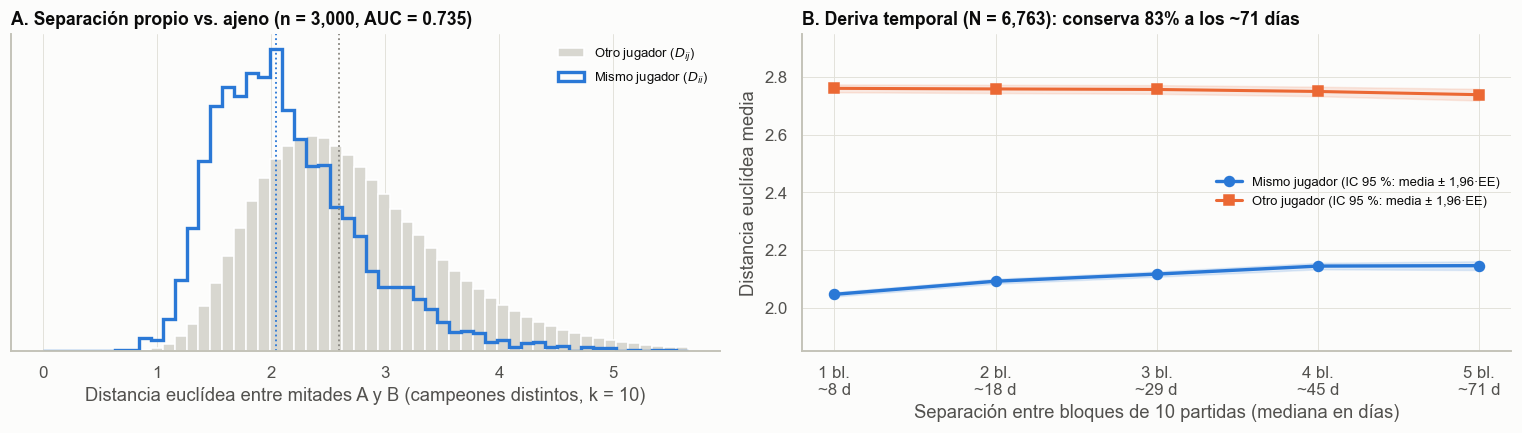

AUC medio por rol principal (k=10, camp. dist.): Top 0.721 · Jungla 0.711 · Mid 0.745 · ADC 0.745 · Soporte 0.745  |  AUC < 0,5: 20.0%


In [9]:
# Distribución de distancias (k=10, campeones distintos) y deriva temporal (6 bloques de 10 partidas)
halves = subsample(make_halves(resid, k=10, mode="campeones_distintos", seed=0), 3000, 0)
pids_d, A_d, B_d = profiles(resid, halves, STYLE_FEATURES)
D_mat = cdist(A_d, B_d)
propia, ajena = np.diag(D_mat), D_mat[~np.eye(len(D_mat), dtype=bool)]
auc_j = pd.Series(row_auc(D_mat), index=pids_d)
info_k = player_info(resid).reindex(pids_d)
auc_rol = auc_j.groupby(info_k["main_lane"]).mean().reindex(CANONICAL_LANES)

BLOQUE, N_BLOQUES = 10, 6
rng_d = np.random.default_rng(0)
largos = n_res[n_res >= BLOQUE * N_BLOQUES].index
sub_t = resid[resid["player_id"].isin(largos)].sort_values(["player_id", "game_creation"])
sub_t = sub_t.groupby("player_id").head(BLOQUE * N_BLOQUES)
sub_t = sub_t.assign(bloque=sub_t.groupby("player_id").cumcount() // BLOQUE)
P_t = sub_t.groupby(["player_id", "bloque"])[STYLE_FEATURES].mean()
jug_t = P_t.index.get_level_values(0).unique()
T_arr = P_t.to_numpy().reshape(len(jug_t), N_BLOQUES, len(STYLE_FEATURES))
otro_arr = T_arr[rng_d.permutation(len(jug_t))]
dias_arr = sub_t.groupby(["player_id", "bloque"])["game_creation"].median().to_numpy().reshape(len(jug_t), N_BLOQUES)

filas_der = []
for delta in range(1, N_BLOQUES):
    # Unidad independiente = jugador (se promedia primero sobre los pares de bloques de cada jugador;
    # la media global es idéntica, pero el EE no infla N contando pares dependientes del mismo jugador).
    mismo_j = np.linalg.norm(T_arr[:, delta:] - T_arr[:, :-delta], axis=2).mean(axis=1)
    aj_j = np.linalg.norm(otro_arr[:, delta:] - T_arr[:, :-delta], axis=2).mean(axis=1)
    gap = ((dias_arr[:, delta:] - dias_arr[:, :-delta]) / 86_400_000).ravel()
    filas_der.append({"delta": delta, "mismo": float(mismo_j.mean()),
                      "mismo_sem": float(mismo_j.std(ddof=1) / np.sqrt(len(mismo_j))),
                      "otro": float(aj_j.mean()),
                      "otro_sem": float(aj_j.std(ddof=1) / np.sqrt(len(aj_j))),
                      "dias": float(np.median(gap))})
deriva = pd.DataFrame(filas_der)
sep_ini = deriva.loc[0, "otro"] - deriva.loc[0, "mismo"]
sep_fin = deriva.iloc[-1]["otro"] - deriva.iloc[-1]["mismo"]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.1))

bins_d = np.linspace(0, np.quantile(ajena, 0.995), 55)
ax1.hist(ajena, bins=bins_d, density=True, color="#d8d7d0", label="Otro jugador ($D_{ij}$)")
ax1.hist(propia, bins=bins_d, density=True, histtype="step", color=CATEGORICAL[0], lw=2.2,
         label="Mismo jugador ($D_{ii}$)")
ax1.axvline(np.median(propia), color=CATEGORICAL[0], ls=":", lw=1.2)
ax1.axvline(np.median(ajena), color=MUTED, ls=":", lw=1.2)
ax1.set_xlabel("Distancia euclídea entre mitades A y B (campeones distintos, k = 10)")
ax1.set_yticks([])
ax1.set_title(f"A. Separación propio vs. ajeno (n = {len(pids_d):,}, AUC = {auc_j.mean():.3f})", loc="left")
ax1.legend(fontsize=8.5, loc="upper right")

for _c, _col, _mk, _ms, _lw, _lbl in (("mismo", CATEGORICAL[0], "o", 6.5, 2.2, "Mismo jugador (IC 95 %: media ± 1,96·EE)"),
                                     ("otro", CATEGORICAL[1], "s", 6.0, 2.0, "Otro jugador (IC 95 %: media ± 1,96·EE)")):
    ax2.plot(deriva["delta"], deriva[_c], color=_col, marker=_mk, ms=_ms, lw=_lw, label=_lbl)
    ax2.fill_between(deriva["delta"], deriva[_c] - 1.96 * deriva[f"{_c}_sem"],
                     deriva[_c] + 1.96 * deriva[f"{_c}_sem"], color=_col, alpha=0.13)
ax2.set_xticks(deriva["delta"], [f"{d} bl.\n~{g:.0f} d" for d, g in zip(deriva["delta"], deriva["dias"])])
ax2.set_ylim(1.85, 2.95)
ax2.set_xlabel("Separación entre bloques de 10 partidas (mediana en días)")
ax2.set_ylabel("Distancia euclídea media")
ax2.set_title(f"B. Deriva temporal (N = {len(jug_t):,}): conserva {sep_fin / sep_ini:.0%} a los ~{deriva['dias'].iloc[-1]:.0f} días",
              loc="left")
ax2.legend(fontsize=8.5, loc="center right")

plt.tight_layout()
plt.show()
print("AUC medio por rol principal (k=10, camp. dist.):",
      " · ".join(f"{LANE_LABELS[r]} {auc_rol[r]:.3f}" for r in CANONICAL_LANES),
      f" |  AUC < 0,5: {(auc_j < 0.5).mean():.1%}")

**Lectura de la Sección 2.**
* **La huella sobrevive al cambio de campeón:** con campeones distintos y $k = 20$ logra **AUC difícil 0,819** ($p = 0{,}001$ por permutación), superando a `crudo` (0,775), `elo_linea` (0,603), `embedding` (0,602) y `pool` (0,283).
* **El ajuste por campeón decide donde importa:** en muestras aleatorias `pool` y `crudo` ganan por compartir campeones; al exigir campeones disjuntos, `pool` colapsa y `embedding` cae al nivel del rol.
* **No es elo ni rol** (AUC difícil cae apenas 0,004 frente al global) y **la deriva es gradual**: a los ~70 días conserva más del 80 % de la separación frente a otro jugador.

# 3. Mejoras de la huella

Para aprovechar las 23 variables redundantes evaluamos mejoras con partición estricta **por jugador**: la mitad aprende pesos o red y la otra mitad —**nunca vista**— mide reidentificación con **campeones distintos** (IC 95 % por bootstrap de jugadores, `huella_mejoras.py`):
1. **Pesos lineales (LDA):** direcciones de $S_w^{-1} S_b$ pesadas por $\sqrt{\lambda}$ (más peso a lo que separa personas que al ruido entre partidas).
2. **Hábitos de timeline completo:** 18 variables residualizadas (control wards, wardeo temprano, orden de habilidades, compras, oro sin gastar, primera vuelta, placas, movimiento).
3. **Métrica no lineal (red contrastiva):** MLP ($d \to 128 \to 128 \to 32$) entrenada con pérdida contrastiva (`InfoNCE`), sobre las 23 estadísticas y sobre **estadísticas + hábitos** (41 variables).
4. **Recencia:** media exponencial sobre 60 previas para reconocer las 10 siguientes.

Conjunto,Método,AUC k=10,IC 95 % (k=10),AUC k=20,IC 95 % (k=20),AUC difícil k=20,Top-1 k=20
23 estadísticas (train),Euclídea (Nivel 1),0.729,[0.721; 0.737],0.815,[0.808; 0.823],0.811,1.5%
23 estadísticas (train),LDA,0.816,[0.810; 0.822],0.883,[0.878; 0.888],0.879,2.3%
23 estadísticas (train),Red contrastiva,0.833,[0.826; 0.838],0.901,[0.896; 0.905],0.894,3.0%
Timelines completos,Estadísticas + hábitos · LDA,0.866,[0.860; 0.872],0.921,[0.915; 0.926],0.918,7.5%
Timelines completos,Estadísticas + hábitos · Red contrastiva,0.890,[0.885; 0.895],0.941,[0.937; 0.945],0.936,8.7%


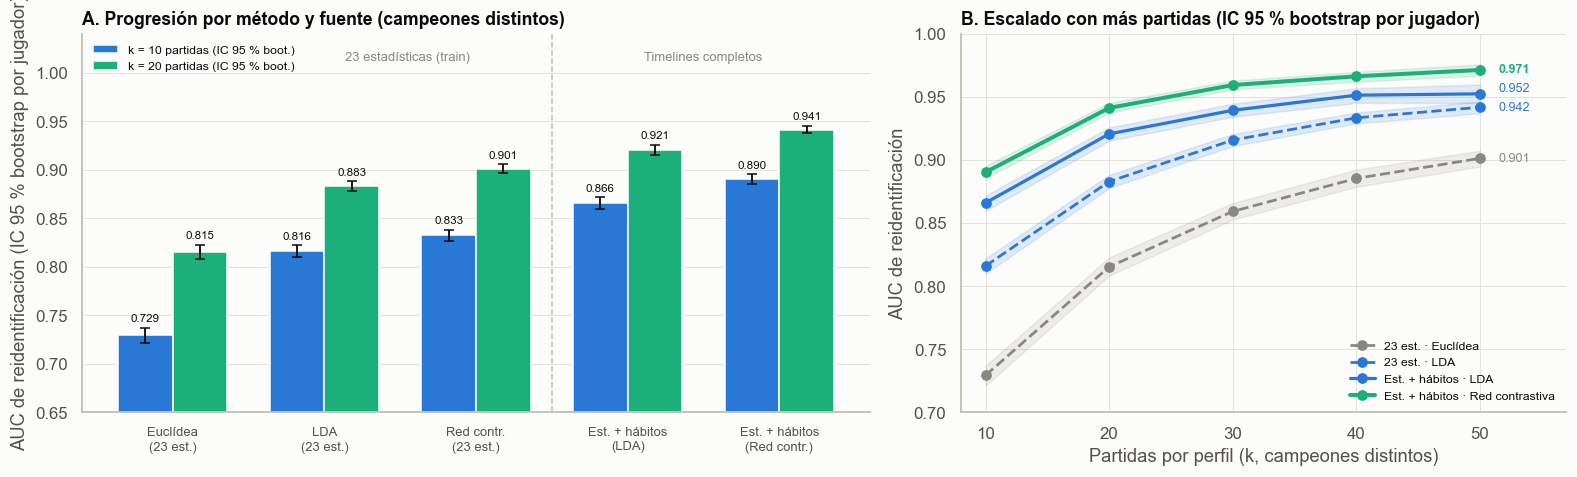

In [10]:
m134 = pd.read_csv(HUELLA / "mejoras_parte134.csv")
m2 = pd.read_csv(HUELLA / "mejoras_parte2.csv")
mk = pd.read_csv(HUELLA / "mejoras_k_grandes.csv")
mrh = pd.read_csv(HUELLA / "mejoras_red_habitos.csv")

# Tabla comparativa limpia (campeones distintos, jugadores no vistos)
cd13 = m134[(m134["muestra"] == "campeones_distintos") & (m134["parte"].astype(str).isin(["1", "3"]))].copy()
cd13["variante"] = cd13["variante"].str.replace(" (referencia)", "", regex=False)
cd13 = cd13.drop_duplicates(["k", "variante"])

cd2 = m2[m2["muestra"] == "campeones_distintos"].copy()
cd_rh = mrh[mrh["muestra"] == "campeones_distintos"].copy()

rows_m3 = []
specs_m3 = [
    (cd13, "23 estadísticas (train)", "euclidea", "Euclídea (Nivel 1)"),
    (cd13, "23 estadísticas (train)", "lda", "LDA"),
    (cd13, "23 estadísticas (train)", "red contrastiva", "Red contrastiva"),
    (cd2, "Timelines completos", "estadísticas + hábitos · lda", "Estadísticas + hábitos · LDA"),
    (cd_rh, "Timelines completos", "estadísticas + hábitos · red contrastiva", "Estadísticas + hábitos · Red contrastiva"),
]
for src, ds, var, lbl in specs_m3:
    r10 = src[(src["variante"] == var) & (src["k"] == 10)].iloc[0]
    r20 = src[(src["variante"] == var) & (src["k"] == 20)].iloc[0]
    rows_m3.append({"Conjunto": ds, "Método": lbl,
                    "AUC k=10": r10["auc"], "IC 95 % (k=10)": f"[{r10['lo']:.3f}; {r10['hi']:.3f}]",
                    "AUC k=20": r20["auc"], "IC 95 % (k=20)": f"[{r20['lo']:.3f}; {r20['hi']:.3f}]",
                    "AUC difícil k=20": r20["auc_dificil"], "Top-1 k=20": r20["top1"]})

tab_m3 = pd.DataFrame(rows_m3)
display(tab_m3.style
        .format({"AUC k=10": "{:.3f}", "AUC k=20": "{:.3f}", "AUC difícil k=20": "{:.3f}", "Top-1 k=20": "{:.1%}"})
        .highlight_max(subset=["AUC k=10", "AUC k=20", "AUC difícil k=20", "Top-1 k=20"], props=RESALTE)
        .hide(axis="index")
        .set_caption("Evolución de la huella en campeones distintos (jugadores no vistos)"))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14.5, 4.5), gridspec_kw={"width_ratios": [1.3, 1.0]})

# Panel A: Progresión k=10 y k=20 con IC 95 % bootstrap por jugador (de mejoras_*.csv)
def _row_m3(df_, var_, k_):
    return df_[(df_["variante"] == var_) & (df_["k"] == k_)].iloc[0]

bar_specs = [
    ("Euclídea\n(23 est.)", _row_m3(cd13, "euclidea", 10), _row_m3(cd13, "euclidea", 20)),
    ("LDA\n(23 est.)", _row_m3(cd13, "lda", 10), _row_m3(cd13, "lda", 20)),
    ("Red contr.\n(23 est.)", _row_m3(cd13, "red contrastiva", 10), _row_m3(cd13, "red contrastiva", 20)),
    ("Est. + hábitos\n(LDA)", _row_m3(cd2, "estadísticas + hábitos · lda", 10),
     _row_m3(cd2, "estadísticas + hábitos · lda", 20)),
    ("Est. + hábitos\n(Red contr.)", cd_rh[cd_rh.k == 10].iloc[0], cd_rh[cd_rh.k == 20].iloc[0]),
]
x_b = np.arange(len(bar_specs))
w_b = 0.36
v10 = np.array([float(r[1]["auc"]) for r in bar_specs])
lo10 = np.array([float(r[1]["lo"]) for r in bar_specs])
hi10 = np.array([float(r[1]["hi"]) for r in bar_specs])
v20 = np.array([float(r[2]["auc"]) for r in bar_specs])
lo20 = np.array([float(r[2]["lo"]) for r in bar_specs])
hi20 = np.array([float(r[2]["hi"]) for r in bar_specs])
ax1.bar(x_b - w_b / 2, v10, width=w_b, color=CATEGORICAL[0], label="k = 10 partidas (IC 95 % boot.)")
ax1.bar(x_b + w_b / 2, v20, width=w_b, color=CATEGORICAL[2], label="k = 20 partidas (IC 95 % boot.)")
ax1.errorbar(x_b - w_b / 2, v10, yerr=[np.maximum(0.0, v10 - lo10), np.maximum(0.0, hi10 - v10)],
             fmt="none", ecolor=INK, elinewidth=1.2, capsize=3.2, zorder=5)
ax1.errorbar(x_b + w_b / 2, v20, yerr=[np.maximum(0.0, v20 - lo20), np.maximum(0.0, hi20 - v20)],
             fmt="none", ecolor=INK, elinewidth=1.2, capsize=3.2, zorder=5)
for xi, (a10, h10, a20, h20) in enumerate(zip(v10, hi10, v20, hi20)):
    ax1.text(xi - w_b / 2, h10 + 0.004, f"{a10:.3f}", ha="center", va="bottom", fontsize=7.6, color=INK)
    ax1.text(xi + w_b / 2, h20 + 0.004, f"{a20:.3f}", ha="center", va="bottom", fontsize=7.6, color=INK)
ax1.axvline(2.5, color=BORDER, ls="--", lw=1.0)
ax1.text(1.55, 1.022, "23 estadísticas (train)", ha="center", va="top", fontsize=8.5, color=MUTED)
ax1.text(3.5, 1.022, "Timelines completos", ha="center", va="top", fontsize=8.5, color=MUTED)
ax1.set_xticks(x_b, [r[0] for r in bar_specs], fontsize=8.5)
ax1.set_ylim(0.65, 1.04)
ax1.set_ylabel("AUC de reidentificación (IC 95 % bootstrap por jugador)")
ax1.set_title("A. Progresión por método y fuente (campeones distintos)", loc="left")
ax1.grid(axis="x", visible=False)
ax1.legend(loc="upper left", fontsize=8.0)

# Panel B: Curva según k (10 a 50) con la misma gramática visual que §§4–5
mk_all = pd.concat([mk, cd_rh], ignore_index=True)
mk_styles = [
    ("23 estadísticas · euclidea", "23 est. · Euclídea", MUTED, "--", 1.8),
    ("23 estadísticas · lda", "23 est. · LDA", CATEGORICAL[0], "--", 1.8),
    ("estadísticas + hábitos · lda", "Est. + hábitos · LDA", CATEGORICAL[0], "-", 2.1),
    ("estadísticas + hábitos · red contrastiva", "Est. + hábitos · Red contrastiva", CATEGORICAL[2], "-", 2.6),
]
ends = []
for var, lbl, col, ls, lw in mk_styles:
    g = mk_all[mk_all["variante"] == var].sort_values("k")
    ax2.plot(g["k"], g["auc"], marker="o", color=col, ls=ls, lw=lw, label=lbl)
    ax2.fill_between(g["k"], g["lo"], g["hi"], color=col, alpha=0.13)
    ends.append((float(g["auc"].iat[-1]), col, lw >= 2.5))
# Separar anotaciones finales si quedan muy cerca
y_prev = -np.inf
for val_e, col_e, is_bold in sorted(ends, key=lambda t: t[0]):
    yy = max(val_e, y_prev + 0.015)
    ax2.annotate(f"{val_e:.3f}", (50, val_e), xytext=(51.5, yy), textcoords="data", va="center",
                 fontsize=8.3, fontweight="bold" if is_bold else "normal", color=col_e)
    y_prev = yy
ax2.set_xticks([10, 20, 30, 40, 50])
ax2.set_xlim(8, 57)
ax2.set_ylim(0.70, 1.00)
ax2.set_xlabel("Partidas por perfil (k, campeones distintos)")
ax2.set_ylabel("AUC de reidentificación")
ax2.set_title("B. Escalado con más partidas (IC 95 % bootstrap por jugador)", loc="left")
ax2.legend(fontsize=8.0, loc="lower right")

plt.tight_layout()
plt.show()

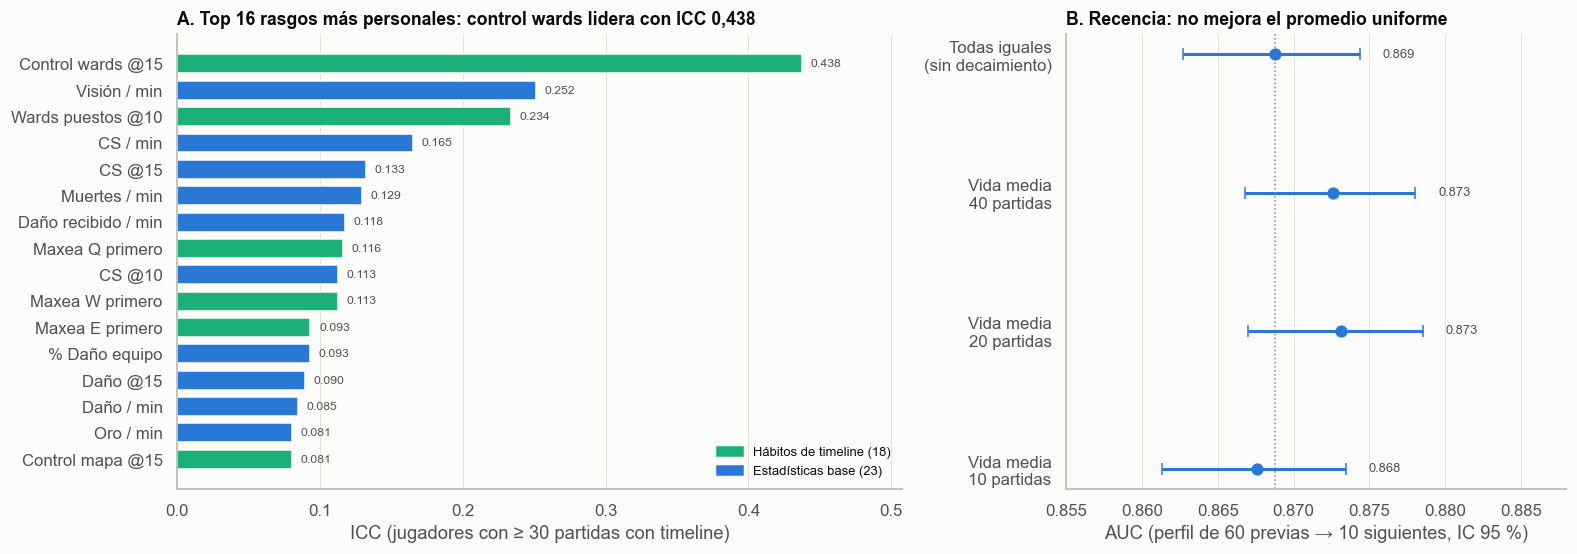

Hábitos menos personales (ICC): movimiento 2–10 = 0.024, avance 5–10 = 0.015.


In [11]:
# Top 16 variables más personales (23 estadísticas + 18 hábitos) y chequeo de recencia
icc_all = pd.Series(json.loads((HUELLA / "icc_habitos.json").read_text(encoding="utf-8"))).sort_values()
HABITOS_SET = {"max_q", "max_w", "max_e", "l1_q", "l1_w", "l1_e", "primera_vuelta_min", "visitas_tienda_10",
               "control_wards_15", "wards_puestos_10", "wards_rotos_15", "nivel6_min", "oro_sin_gastar_med",
               "movimiento_2_10", "avance_5_10", "primera_muerte_min", "placas_14", "control_15"}
top_icc = icc_all.tail(16)

r4 = m134[m134["parte"].astype(str) == "4"].copy()
r4["etiqueta"] = r4["variante"].map({
    "todas iguales": "Todas iguales\n(sin decaimiento)",
    "vida media 40 partidas": "Vida media\n40 partidas",
    "vida media 20 partidas": "Vida media\n20 partidas",
    "vida media 10 partidas": "Vida media\n10 partidas",
})

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14.5, 5.2), gridspec_kw={"width_ratios": [1.45, 1.0]})

cols_icc = [CATEGORICAL[2] if k in HABITOS_SET else CATEGORICAL[0] for k in top_icc.index]
lbls_icc = [FEAT_LABELS.get(k, k) for k in top_icc.index]
ax1.barh(lbls_icc, top_icc.values, color=cols_icc, height=0.72)
for yi, v in enumerate(top_icc.values):
    ax1.text(v + 0.006, yi, f"{v:.3f}", va="center", fontsize=8, color=INK_2)
ax1.set_xlim(0, top_icc.max() * 1.16)
ax1.set_xlabel("ICC (jugadores con ≥ 30 partidas con timeline)")
ax1.set_title("A. Top 16 rasgos más personales: control wards lidera con ICC 0,438", loc="left")
ax1.grid(axis="y", visible=False)
ax1.legend(handles=[Patch(color=CATEGORICAL[2], label="Hábitos de timeline (18)"),
                    Patch(color=CATEGORICAL[0], label="Estadísticas base (23)")],
           loc="lower right", fontsize=8.5)

# Panel B: Recencia (IC 95 % completamente superpuestos)
y_r = np.arange(len(r4))
xerr = np.vstack([r4["auc"] - r4["lo"], r4["hi"] - r4["auc"]])
ax2.errorbar(r4["auc"], y_r, xerr=xerr, fmt="o", color=CATEGORICAL[0], ms=7, lw=2, capsize=4)
for yi, (_, rr) in enumerate(r4.iterrows()):
    ax2.text(rr["hi"] + 0.0015, yi, f"{rr['auc']:.3f}", va="center", fontsize=8.5, color=INK_2)
ax2.axvline(r4.iloc[0]["auc"], color=MUTED, ls=":", lw=1.0)
ax2.set_yticks(y_r, r4["etiqueta"])
ax2.invert_yaxis()
ax2.set_xlim(0.855, 0.888)
ax2.set_xlabel("AUC (perfil de 60 previas → 10 siguientes, IC 95 %)")
ax2.set_title("B. Recencia: no mejora el promedio uniforme", loc="left")
ax2.grid(axis="y", visible=False)

plt.tight_layout()
plt.show()
print(f"Hábitos menos personales (ICC): movimiento 2–10 = {icc_all['movimiento_2_10']:.3f}, "
      f"avance 5–10 = {icc_all['avance_5_10']:.3f}.")

**Lectura de la Sección 3.**
* **Pesar variables y aprender la métrica multiplica la señal:** sobre las 23 estadísticas, LDA con 10 partidas ($0{,}816$) iguala a la euclídea con 20 ($0{,}815$), y la red contrastiva sube a $0{,}901$ ($k = 20$) en jugadores nunca vistos.
* **La combinación ganadora es la red contrastiva sobre estadísticas + hábitos (timelines completos):** alcanza **$0{,}890$ ($k = 10$)**, **$0{,}941$ ($k = 20$, Top-1 $8{,}7\ \%$)** y **$0{,}971$ ($k = 50$, Top-1 $28{,}5\ \%$)**, superando en $+0{,}020\text{–}0{,}024$ a LDA sobre los mismos datos ($0{,}866$ / $0{,}921$).
* **Control wards @15 lidera el ICC ($0{,}438$)** —casi el doble que `Visión / min` ($0{,}252$)—, seguido de wards tempranos y orden de habilidades; movimiento y avance son casi nulos ($\le 0{,}024$).
* **La recencia no suma** ($0{,}869$ vs. $0{,}873$, IC superpuestos), y la caída del AUC difícil sigue en $0{,}003\text{–}0{,}007$.

# 4. Nivel 2: verificación con jugadores no vistos

El Nivel 1 ordena distancias por jugador; un sistema real necesita un **umbral único global** para decidir si dos perfiles (con campeones distintos) son de la misma persona. En jugadores nunca vistos medimos (`nivel2.csv`, PROJECT_SUMMARY §10.5):
* **ROC-AUC:** capacidad global de separar pares genuinos (misma persona) de impostores (dos personas distintas); $1{,}0$ es perfecto, $0{,}5$ es azar.
* **EER (*Equal Error Rate*):** tasa de error en el umbral donde las **falsas aceptaciones** (FAR: aceptar un impostor) igualan a los **falsos rechazos** (FRR: rechazar a la misma persona); **menor es mejor**.
* **TAR @ FAR = 1 %:** porcentaje de genuinos correctamente reconocidos (*True Acceptance Rate*) cuando se exige aceptar como máximo **1 % de impostores**; **mayor es mejor**.

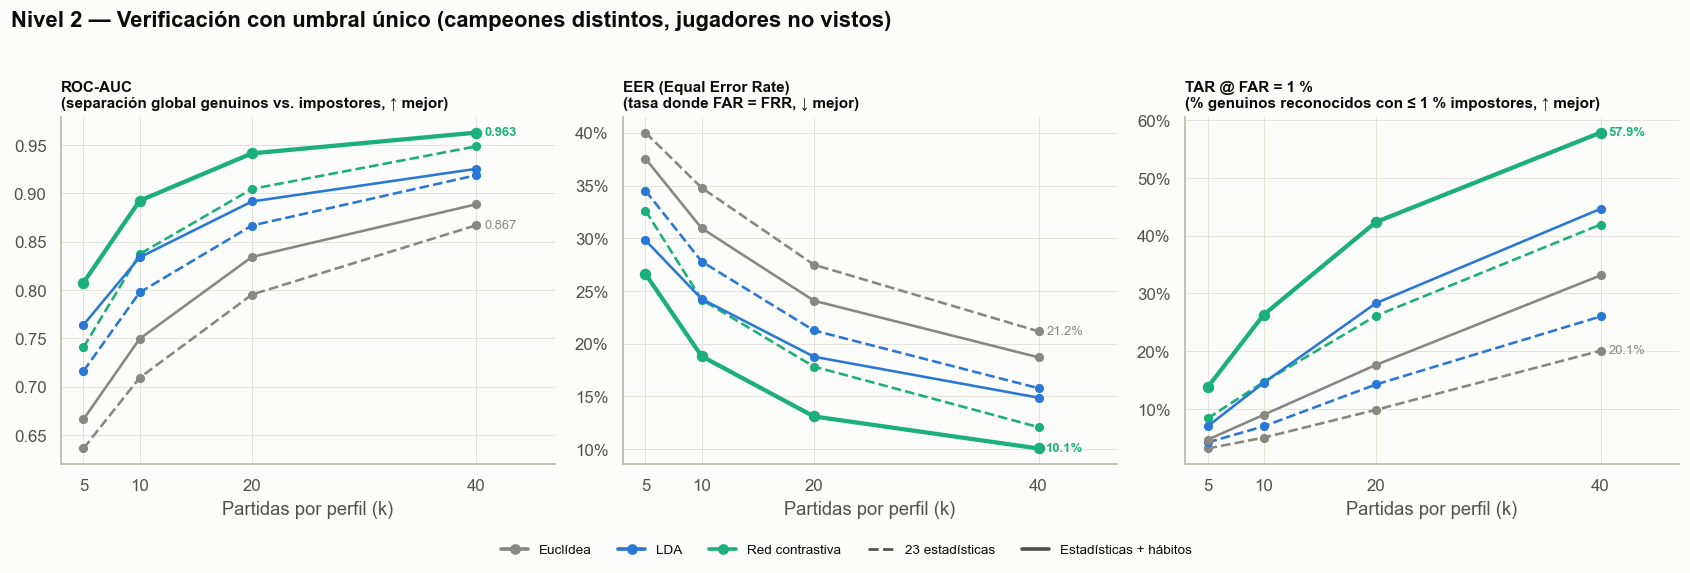

Datos,Método,AUC k=20,AUC k=40,EER k=20,EER k=40,TAR@1% k=20,TAR@1% k=40
23 estadísticas,Euclídea,0.795,0.867,27.5%,21.2%,9.8%,20.1%
23 estadísticas,LDA,0.867,0.919,21.3%,15.8%,14.2%,26.0%
23 estadísticas,Red contrastiva,0.905,0.949,17.8%,12.1%,26.1%,41.9%
Est. + hábitos,Euclídea,0.834,0.889,24.1%,18.7%,17.6%,33.1%
Est. + hábitos,LDA,0.892,0.925,18.8%,14.9%,28.3%,44.7%
Est. + hábitos,Red contrastiva,0.941,0.963,13.1%,10.1%,42.4%,57.9%


In [12]:
n2 = pd.read_csv(HUELLA / "nivel2.csv")
n2t = n2[n2["impostores"] == "todos"].copy()

# Gramática visual consistente para Secciones 4 y 5: color = método, trazo = conjunto de datos
MET_COL = {"euclídea": MUTED, "LDA": CATEGORICAL[0], "red contrastiva": CATEGORICAL[2]}
MET_LBL = {"euclídea": "Euclídea", "LDA": "LDA", "red contrastiva": "Red contrastiva"}
DAT_LS = {"23 estadísticas (train)": "--", "estadísticas + hábitos": "-"}
DAT_LBL = {"23 estadísticas (train)": "23 estadísticas", "estadísticas + hábitos": "Est. + hábitos"}

fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.7))
metricas_n2 = [
    ("roc_auc", "ROC-AUC\n(separación global genuinos vs. impostores, ↑ mejor)", False),
    ("eer", "EER (Equal Error Rate)\n(tasa donde FAR = FRR, ↓ mejor)", True),
    ("tar_far1", "TAR @ FAR = 1 %\n(% genuinos reconocidos con ≤ 1 % impostores, ↑ mejor)", True),
]

for ax, (col, tit, is_pct) in zip(axes, metricas_n2):
    for dat in ["23 estadísticas (train)", "estadísticas + hábitos"]:
        for rep in ["euclídea", "LDA", "red contrastiva"]:
            s = n2t[(n2t["datos"] == dat) & (n2t["representacion"] == rep)].sort_values("k")
            ganador = (dat == "estadísticas + hábitos") and (rep == "red contrastiva")
            ax.plot(s["k"], s[col], color=MET_COL[rep], ls=DAT_LS[dat], marker="o",
                    ms=6.5 if ganador else 5, lw=2.8 if ganador else 1.7)
            if ganador or (dat == "23 estadísticas (train)" and rep == "euclídea"):
                v40 = float(s[col].iat[-1])
                txt = f"{v40:.1%}" if is_pct else f"{v40:.3f}"
                ax.annotate(txt, (40, v40), xytext=(5, 0), textcoords="offset points", va="center",
                            fontsize=8.5, fontweight="bold" if ganador else "normal", color=MET_COL[rep])
    ax.set_xticks([5, 10, 20, 40])
    ax.set_xlim(3, 47)
    ax.set_xlabel("Partidas por perfil (k)")
    ax.set_title(tit, loc="left", fontsize=10.0)
    if is_pct:
        ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))

leg_elems = [
    Line2D([0], [0], color=MET_COL[r], lw=2.4, marker="o", label=MET_LBL[r]) for r in ["euclídea", "LDA", "red contrastiva"]
] + [
    Line2D([0], [0], color=INK_2, lw=1.8, ls="--", label="23 estadísticas"),
    Line2D([0], [0], color=INK_2, lw=2.4, ls="-", label="Estadísticas + hábitos"),
]
fig.legend(handles=leg_elems, loc="lower center", bbox_to_anchor=(0.5, -0.06), ncol=5, fontsize=8.8)
fig.suptitle("Nivel 2 — Verificación con umbral único (campeones distintos, jugadores no vistos)",
             x=0.01, ha="left", fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

# Tabla compacta: k = 20 y k = 40 (ROC-AUC, EER y TAR@FAR=1 %)
filas_n2 = []
for dat in ["23 estadísticas (train)", "estadísticas + hábitos"]:
    for rep in ["euclídea", "LDA", "red contrastiva"]:
        s = n2t[(n2t["datos"] == dat) & (n2t["representacion"] == rep)].set_index("k")
        filas_n2.append({
            "Datos": DAT_LBL[dat], "Método": MET_LBL[rep],
            "AUC k=20": s.loc[20, "roc_auc"], "AUC k=40": s.loc[40, "roc_auc"],
            "EER k=20": s.loc[20, "eer"], "EER k=40": s.loc[40, "eer"],
            "TAR@1% k=20": s.loc[20, "tar_far1"], "TAR@1% k=40": s.loc[40, "tar_far1"],
        })
tab_n2 = pd.DataFrame(filas_n2)
display(tab_n2.style
        .format({"AUC k=20": "{:.3f}", "AUC k=40": "{:.3f}",
                 "EER k=20": "{:.1%}", "EER k=40": "{:.1%}",
                 "TAR@1% k=20": "{:.1%}", "TAR@1% k=40": "{:.1%}"})
        .highlight_max(subset=["AUC k=20", "AUC k=40", "TAR@1% k=20", "TAR@1% k=40"], props=RESALTE)
        .highlight_min(subset=["EER k=20", "EER k=40"], props=RESALTE)
        .hide(axis="index")
        .set_caption("Nivel 2: verificación con umbral único (campeones distintos, jugadores no vistos)"))

**Lectura de la Sección 4.**
* **La red contrastiva sobre estadísticas + hábitos domina en todos los tamaños de perfil:** ROC-AUC de **$0{,}808$** ($k = 5$) a **$0{,}963$** ($k = 40$), frente a $0{,}636\text{–}0{,}867$ de la huella euclídea inicial.
* Con 40 partidas alcanza **EER = 10,1 %** y **TAR@FAR = 1 % de 57,9 %** (casi el triple del 20,1 % original).
* Frente a impostores del mismo tier y línea, la caída máxima de ROC-AUC es de apenas **0,002 a 0,012**: el modelo generaliza a personas nuevas sin depender de elo ni de rol.

# 5. Reconocimiento de patrones intra-cuenta: boosting y cuentas compartidas

Para detectar **boosting** o **cuentas compartidas** sin etiquetas previas aplicamos **aprendizaje no supervisado dentro de cada cuenta real** sobre los embeddings de la red contrastiva (41 variables: 23 estadísticas + 18 hábitos, proyectados **fuera de muestra mediante 2-fold por jugador** para que ninguna cuenta sea evaluada por una red que la vio entrenar, `huella_patrones_cuenta.py`).

1. **Garantía de ortogonalidad al resultado (`win`):** como cada variable se residualizó dentro de `(campeón, línea, resultado)`, ganar o perder no desplaza la huella. Sobre 7.068 jugadores, la distancia entre sus victorias y sus derrotas es $0{,}629$ frente a $0{,}606$ en una partición aleatoria (**ratio $1{,}04$**): un subgrupo con huella distinta y winrate alto no es un artefacto de "partidas ganadas".
2. **Clustering no supervisado por cuenta:** en cada cuenta con $\ge 50$ partidas con timeline ($N = 5.843$) agrupamos sus bloques consecutivos de 5 partidas con **K-Means ($k = 2$, mínimo 2 bloques = 10 partidas por grupo)** usando **solo** los embeddings de estilo (sin ver `win`, fecha ni horario).
3. **Cruce con winrate (ambos signos + FDR):** comparamos el subgrupo minoritario ($C_{\text{alt}}$) contra el perfil base ($C_{\text{base}}$) por separación estilística (`d_estilo ≥ p95` y `silhouette ≥ p90`) y cambio de winrate ($\Delta\text{WR} \ge +15\ \text{pp}$ o $\le -15\ \text{pp}$, test exacto de Fisher $p < 0{,}05$, acompañado del control de múltiples pruebas Benjamini-Hochberg FDR):

| | **WR similar ($|\Delta\text{WR}| < 12\ \text{pp}$)** | **Subida de WR ($\Delta\text{WR} \ge +15\ \text{pp}$, $p < 0{,}05$)** | **Caída de WR ($\Delta\text{WR} \le -15\ \text{pp}$, $p < 0{,}05$)** |
| :--- | :--- | :--- | :--- |
| **Huella homogénea** | Cuenta normal | **Racha buena (*hot streak*)** → se descarta | Racha mala (en *Normal / resto*) |
| **Huella muy distinta** | Candidata a **cuenta compartida** | Candidata a **boosting** | **Huella distinta + caída WR** *(espejo: préstamo/compra)* |

4. **Corroboración independiente:** contrastamos los grupos contra **cuatro señales que el clustering nunca vio** —cambio de horario (`TVD` en ART), **cambio de rol (`TVD`)**, **cambio de tipo de campeón** (`TVD` sobre 10 arquetipos construidos con las 17 estadísticas de `champions_by_lane.csv`) y contigüidad temporal— y verificamos la persistencia del patrón restringiendo al **rol principal** ($N = 4.287$).

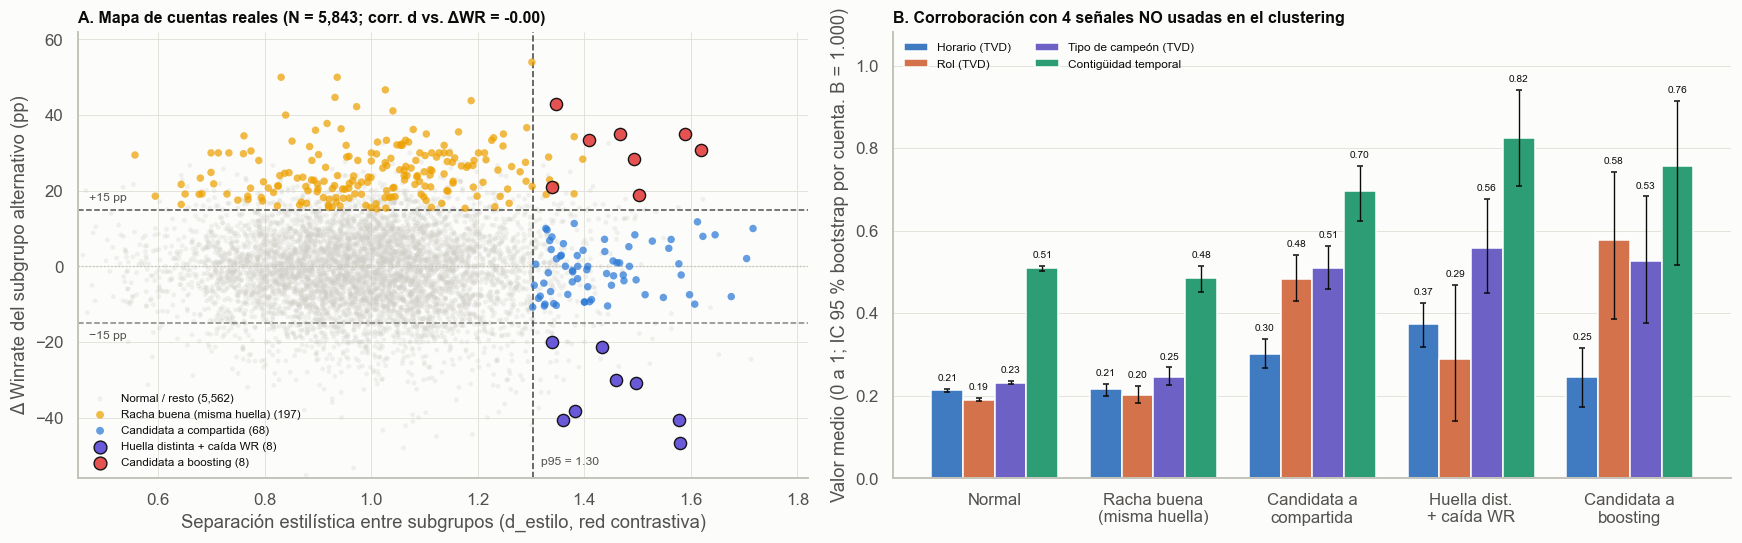

,Cuentas,%,d_estilo,Sil.,WR base,WR subg.,ΔWR,Horario,Rol,Tipo camp.,Contig.
Grupo,,,,,,,,,,,
Normal / resto,"5,562",95.19%,0.99,0.12,51.2%,50.1%,-1.2%,0.21,0.19,0.23,0.51
Racha buena (misma huella),197,3.37%,1.01,0.13,42.1%,67.4%,+25.3%,0.21,0.20,0.25,0.48
Candidata a compartida,68,1.16%,1.44,0.24,50.3%,49.4%,-0.9%,0.30,0.48,0.51,0.70
Huella distinta + caída WR,8,0.14%,1.45,0.22,59.2%,25.6%,-33.6%,0.37,0.29,0.56,0.82
Candidata a boosting,8,0.14%,1.47,0.28,39.3%,69.9%,+30.7%,0.25,0.58,0.53,0.76


Control solo rol principal (N = 4,287): corr(d_estilo, ΔWR) = -0.012 | corr(d_estilo, horario) = +0.157 | corr(d_estilo, tipo camp.) = +0.198 | ortogonalidad W vs. L = 0.629 vs. aleatoria 0.606 (ratio 1.04).
Control por múltiples pruebas (Benjamini-Hochberg FDR): candidatas a boosting con q < 0,05 global = 0 (q < 0,10 condicional al filtro de estilo = 0); con 10–30 partidas por subgrupo el filtro sirve para priorizar candidatas, no como prueba definitiva sin etiquetas de Riot.


In [13]:
pc_all = pd.read_csv(HUELLA / "patrones_cuentas_todos_roles.csv")
pc_rol = pd.read_csv(HUELLA / "patrones_cuentas.csv")
orto = json.loads((HUELLA / "patrones_ortogonalidad.json").read_text(encoding="utf-8"))

# Clasificación con ambos signos de ΔWR (p95 de d_estilo y p90 de silhouette + Fisher p < 0,05)
thr_d = float(pc_all["d_estilo"].quantile(0.95))
thr_s = float(pc_all["silhouette"].quantile(0.90))
est_all = (pc_all["d_estilo"] >= thr_d) & (pc_all["silhouette"] >= thr_s)
wr_up = (pc_all["delta_wr"] >= 0.15) & (pc_all["p_wr_gt"] < 0.05)
wr_dn = (pc_all["delta_wr"] <= -0.15) & (pc_all["p_wr_lt"] < 0.05)
pc_all["grupo"] = np.select(
    [est_all & wr_up, est_all & wr_dn, est_all & (pc_all["delta_wr"].abs() < 0.12), (~est_all) & wr_up],
    ["Candidata a boosting", "Huella distinta + caída WR", "Candidata a compartida", "Racha buena (misma huella)"],
    default="Normal / resto",
)

CAT_ORDER = [
    "Normal / resto",
    "Racha buena (misma huella)",
    "Candidata a compartida",
    "Huella distinta + caída WR",
    "Candidata a boosting",
]
CAT_COL = {
    "Normal / resto": "#cfcec6",
    "Racha buena (misma huella)": CATEGORICAL[3],
    "Candidata a compartida": CATEGORICAL[0],
    "Huella distinta + caída WR": CATEGORICAL[6],
    "Candidata a boosting": CATEGORICAL[7],
}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16.0, 5.1), gridspec_kw={"width_ratios": [1.08, 1.24]})

# Panel A: Mapa de cuentas reales (separación de huella vs ΔWR, mostrando ambos signos)
for g in CAT_ORDER:
    sub = pc_all[pc_all["grupo"] == g]
    is_hi = g in ("Candidata a boosting", "Huella distinta + caída WR")
    is_norm = g == "Normal / resto"
    ax1.scatter(sub["d_estilo"], sub["delta_wr"] * 100,
                color=CAT_COL[g], alpha=0.28 if is_norm else (0.95 if is_hi else 0.72),
                s=64 if is_hi else (24 if not is_norm else 10),
                edgecolors=INK if is_hi else "none", linewidths=0.9 if is_hi else 0,
                zorder=5 if is_hi else (3 if not is_norm else 1),
                label=f"{g} ({len(sub):,})")
ax1.axvline(thr_d, color=INK_2, ls="--", lw=1.1)
ax1.axhline(15.0, color=INK_2, ls="--", lw=1.0)
ax1.axhline(-15.0, color=INK_2, ls="--", lw=1.0, alpha=0.7)
ax1.axhline(0.0, color=BORDER, ls=":", lw=0.9)
ax1.text(thr_d + 0.015, -53, f"p95 = {thr_d:.2f}", fontsize=8.0, color=INK_2, ha="left", va="bottom")
ax1.text(0.47, 16.8, "+15 pp", fontsize=8.0, color=INK_2, ha="left", va="bottom")
ax1.text(0.47, -17.0, "−15 pp", fontsize=8.0, color=INK_2, ha="left", va="top")
ax1.set_xlim(0.45, 1.82)
ax1.set_ylim(-56, 62)
ax1.set_xlabel("Separación estilística entre subgrupos (d_estilo, red contrastiva)")
ax1.set_ylabel("Δ Winrate del subgrupo alternativo (pp)")
ax1.set_title(f"A. Mapa de cuentas reales (N = {len(pc_all):,}; corr. d vs. ΔWR = {pc_all['d_estilo'].corr(pc_all['delta_wr']):+.2f})",
              loc="left", fontsize=10.5)
ax1.legend(loc="lower left", fontsize=7.6, markerscale=1.05)

# Panel B: Corroboración con 4 señales independientes que el clustering NO vio
agg_cat = pc_all.groupby("grupo").agg(
    Cuentas=("player_id", "size"),
    d_estilo=("d_estilo", "mean"),
    sil=("silhouette", "mean"),
    wr_base=("wr_base", "mean"),
    wr_alt=("wr_alt", "mean"),
    delta_wr=("delta_wr", "mean"),
    tvd_hora=("tvd_hora", "mean"),
    tvd_rol=("tvd_rol", "mean"),
    tvd_tipo_camp=("tvd_tipo_camp", "mean"),
    contiguidad=("contiguidad", "mean"),
    pct_main_alt=("pct_main_alt", "mean"),
).reindex(CAT_ORDER)

cor_cols = [
    ("tvd_hora", "Horario (TVD)"),
    ("tvd_rol", "Rol (TVD)"),
    ("tvd_tipo_camp", "Tipo de campeón (TVD)"),
    ("contiguidad", "Contigüidad temporal"),
]
short_cat = {
    "Normal / resto": "Normal",
    "Racha buena (misma huella)": "Racha buena\n(misma huella)",
    "Candidata a compartida": "Candidata a\ncompartida",
    "Huella distinta + caída WR": "Huella dist.\n+ caída WR",
    "Candidata a boosting": "Candidata a\nboosting",
}
_rng_p5 = np.random.default_rng(5)
_B_P5 = 1000
_cor_rows = []
for g_cat in CAT_ORDER:
    sub_g = pc_all[pc_all["grupo"] == g_cat]
    idx_b = _rng_p5.integers(0, len(sub_g), size=(_B_P5, len(sub_g)))
    for col_c, lbl_c in cor_cols:
        arr_c = sub_g[col_c].to_numpy(float)
        bm_c = arr_c[idx_b].mean(axis=1)
        _cor_rows.append({"grupo": g_cat, "Grupo": short_cat[g_cat], "Señal": lbl_c,
                          "Valor": float(arr_c.mean()),
                          "lo": float(np.percentile(bm_c, 2.5)), "hi": float(np.percentile(bm_c, 97.5))})
cor_long = pd.DataFrame(_cor_rows)
ord_g5 = [short_cat[g] for g in CAT_ORDER]
ord_s5 = [lbl_c for _, lbl_c in cor_cols]
sns.barplot(data=cor_long, x="Grupo", y="Valor", hue="Señal",
            order=ord_g5, hue_order=ord_s5,
            palette=[CATEGORICAL[0], CATEGORICAL[1], CATEGORICAL[6], CATEGORICAL[2]], ax=ax2)
hi5_max = 0.0
for cont, lbl_c in zip(ax2.containers, ord_s5):
    ds = cor_long[cor_long["Señal"] == lbl_c].set_index("Grupo").loc[ord_g5]
    for bar, g_s in zip(cont, ord_g5):
        v, lo_, hi_ = float(ds.loc[g_s, "Valor"]), float(ds.loc[g_s, "lo"]), float(ds.loc[g_s, "hi"])
        xc = bar.get_x() + bar.get_width() / 2
        ax2.errorbar(xc, v, yerr=[[max(0.0, v - lo_)], [max(0.0, hi_ - v)]],
                     fmt="none", ecolor=INK, elinewidth=0.9, capsize=2.0, zorder=5)
        ax2.text(xc, hi_ + 0.015, f"{v:.2f}", ha="center", va="bottom", fontsize=6.6, color=INK)
        hi5_max = max(hi5_max, hi_)
ax2.set_ylim(0, max(1.06, hi5_max + 0.14))
ax2.set_xlabel("")
ax2.set_ylabel(f"Valor medio (0 a 1; IC 95 % bootstrap por cuenta, B = {_B_P5:,})".replace(",", "."))
ax2.set_title("B. Corroboración con 4 señales NO usadas en el clustering", loc="left", fontsize=10.5)
ax2.grid(axis="x", visible=False)
ax2.legend(title="", fontsize=7.8, loc="upper left", ncol=2)

plt.tight_layout()
plt.show()

tab_q = pd.DataFrame({
    "Cuentas": agg_cat["Cuentas"],
    "%": agg_cat["Cuentas"] / len(pc_all),
    "d_estilo": agg_cat["d_estilo"],
    "Sil.": agg_cat["sil"],
    "WR base": agg_cat["wr_base"],
    "WR subg.": agg_cat["wr_alt"],
    "ΔWR": agg_cat["delta_wr"],
    "Horario": agg_cat["tvd_hora"],
    "Rol": agg_cat["tvd_rol"],
    "Tipo camp.": agg_cat["tvd_tipo_camp"],
    "Contig.": agg_cat["contiguidad"],
}).rename_axis("Grupo")
display(tab_q.style
        .format({"Cuentas": "{:,}", "%": "{:.2%}", "d_estilo": "{:.2f}", "Sil.": "{:.2f}",
                 "WR base": "{:.1%}", "WR subg.": "{:.1%}", "ΔWR": "{:+.1%}",
                 "Horario": "{:.2f}", "Rol": "{:.2f}", "Tipo camp.": "{:.2f}", "Contig.": "{:.2f}"})
        .highlight_max(subset=["d_estilo", "Sil.", "ΔWR", "Horario", "Rol", "Tipo camp.", "Contig."], props=RESALTE)
        .set_caption(f"Resumen por grupo con ambos signos de ΔWR (N = {len(pc_all):,} cuentas Master+ con ≥ 50 partidas; Horario, Rol y Tipo camp. en TVD 0–1)"))
n_fdr_g = int((est_all & wr_up & (pc_all["q_wr_gt"] < 0.05)).sum())
n_fdr_c = int((est_all & wr_up & (pc_all["q_wr_two_en_est"] < 0.10)).sum())
print(f"Control solo rol principal (N = {len(pc_rol):,}): corr(d_estilo, ΔWR) = {orto['corr_d_estilo_delta_wr']:+.3f} "
      f"| corr(d_estilo, horario) = {orto['corr_d_estilo_tvd_hora']:+.3f} "
      f"| corr(d_estilo, tipo camp.) = {pc_rol['d_estilo'].corr(pc_rol['tvd_tipo_camp']):+.3f} "
      f"| ortogonalidad W vs. L = {orto['dist_win_vs_loss_media']:.3f} vs. aleatoria {orto['dist_aleatoria_media']:.3f} "
      f"(ratio {orto['ratio_media']:.2f}).")
print(f"Control por múltiples pruebas (Benjamini-Hochberg FDR): candidatas a boosting con q < 0,05 global = {n_fdr_g} "
      f"(q < 0,10 condicional al filtro de estilo = {n_fdr_c}); con 10–30 partidas por subgrupo el filtro sirve para "
      "priorizar candidatas, no como prueba definitiva sin etiquetas de Riot.")

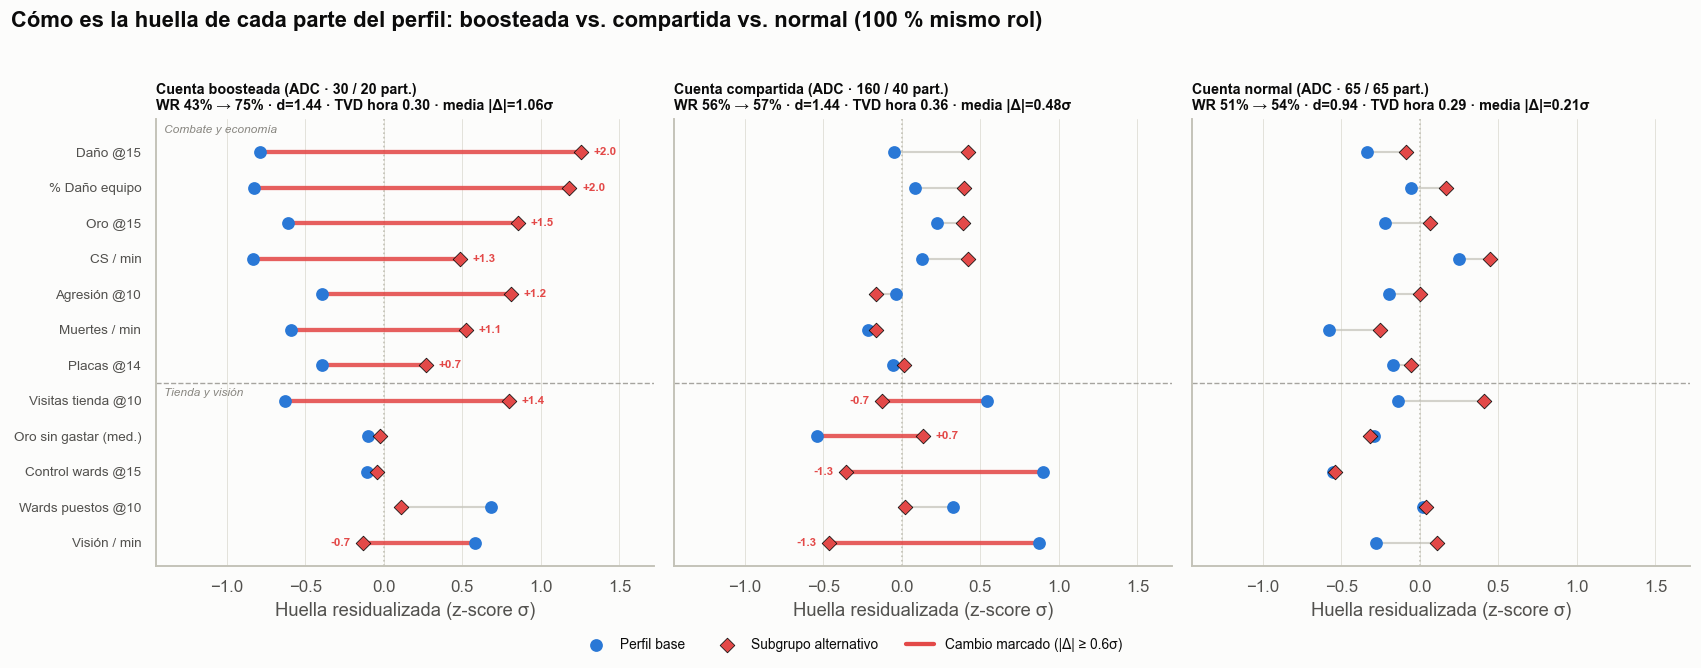

,Δ Cuenta boosteada (WR 43%→75%),Δ Cuenta compartida (WR 56%→57%),Δ Cuenta normal (WR 51%→54%)
Variable de huella (σ),,,
Daño @15,+2.04,+0.47,+0.25
% Daño equipo,+2.01,+0.31,+0.22
Oro @15,+1.47,+0.16,+0.29
CS / min,+1.32,+0.30,+0.20
Agresión @10,+1.20,-0.13,+0.20
Muertes / min,+1.11,+0.05,+0.32
Placas @14,+0.66,+0.07,+0.11
Visitas tienda @10,+1.42,-0.66,+0.55
Oro sin gastar (med.),+0.08,+0.68,-0.03


In [14]:
# Huella detallada de cada parte del perfil (Perfil base vs. Subgrupo alternativo)
# en 3 cuentas reales anonimizadas del mismo rol principal (100 % ADC): boosteada, compartida y normal
ej = pd.read_csv(HUELLA / "patrones_huellas_ejemplos.csv")
pad = pd.read_csv(HUELLA / "patrones_huellas_padron.csv").set_index("variable")

VARS_HUELLA = [
    # Combate y economía (7)
    "damage_15", "damage_share_pct", "gold_15", "cs_pm", "early_aggression_10", "deaths_pm", "placas_14",
    # Gestión de tienda y hábitos de visión (5)
    "visitas_tienda_10", "oro_sin_gastar_med", "control_wards_15", "wards_puestos_10", "vision_pm",
]
N_COMB = 7
TIPOS = ["Cuenta boosteada", "Cuenta compartida", "Cuenta normal"]
UMBRAL_DELTA = 0.60

fig, axes = plt.subplots(1, 3, figsize=(15.6, 5.6), sharey=True)
ys = np.arange(len(VARS_HUELLA))

for ax, tipo in zip(axes, TIPOS):
    s = ej[ej["tipo"] == tipo].set_index("variable").reindex(VARS_HUELLA)
    meta = ej[ej["tipo"] == tipo].iloc[0]
    b_vals = s["base"].to_numpy()
    a_vals = s["alt"].to_numpy()
    d_vals = s["delta"].to_numpy()

    ax.axvline(0.0, color=BORDER, ls=":", lw=1.1, zorder=1)
    ax.axhline(N_COMB - 0.5, color=MUTED, ls="--", lw=0.9, alpha=0.75, zorder=1)

    for y, bv, av, dv in zip(ys, b_vals, a_vals, d_vals):
        fuerte = abs(dv) >= UMBRAL_DELTA
        ax.plot([bv, av], [y, y], color=CATEGORICAL[7] if fuerte else "#c6c5bc",
                lw=2.8 if fuerte else 1.4, alpha=0.88 if fuerte else 0.75, zorder=2)
        if fuerte:
            x_txt = max(bv, av) + 0.08 if dv > 0 else min(bv, av) - 0.08
            ha = "left" if dv > 0 else "right"
            ax.text(x_txt, y, f"{dv:+.1f}", va="center", ha=ha, fontsize=7.6,
                    fontweight="bold", color=CATEGORICAL[7])

    ax.scatter(b_vals, ys, color=CATEGORICAL[0], marker="o", s=54, zorder=4, label="Perfil base")
    ax.scatter(a_vals, ys, color=CATEGORICAL[7], marker="D", s=46, edgecolors=INK, linewidths=0.5,
               zorder=5, label="Subgrupo alternativo")

    lane_es = LANE_LABELS.get(meta["main_lane"], meta["main_lane"])
    med_abs = float(np.abs(d_vals).mean())
    ax.set_xlim(-1.45, 1.72)
    ax.set_xlabel("Huella residualizada (z-score σ)")
    ax.set_title(
        f"{tipo} ({lane_es} · {int(meta['partidas_base'])} / {int(meta['partidas_alt'])} part.)\n"
        f"WR {meta['wr_base']:.0%} → {meta['wr_alt']:.0%} · d={meta['d_estilo']:.2f} · "
        f"TVD hora {meta['tvd_hora']:.2f} · media |Δ|={med_abs:.2f}σ",
        loc="left", fontsize=9.4,
    )
    ax.grid(axis="y", visible=False)

axes[0].set_yticks(ys, [FEAT_LABELS[v] for v in VARS_HUELLA], fontsize=8.8)
axes[0].set_ylim(len(VARS_HUELLA) - 0.35, -0.92)
axes[0].text(-1.40, -0.62, "Combate y economía", fontsize=7.8, color=MUTED, style="italic", va="center")
axes[0].text(-1.40, N_COMB - 0.36, "Tienda y visión", fontsize=7.8, color=MUTED, style="italic", va="top")

handles_h, labels_h = axes[0].get_legend_handles_labels()
handles_h.append(Line2D([0], [0], color=CATEGORICAL[7], lw=2.8, label=f"Cambio marcado (|Δ| ≥ {UMBRAL_DELTA:.1f}σ)"))
fig.legend(handles=handles_h, loc="lower center", bbox_to_anchor=(0.5, -0.04), ncol=3, fontsize=9)
fig.suptitle("Cómo es la huella de cada parte del perfil: boosteada vs. compartida vs. normal (100 % mismo rol)",
             x=0.01, ha="left", fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

# Tabla compacta de deltas (Subgrupo alternativo − Perfil base, en σ residualizados) + resumen del padrón
cols_data = {}
res_ej = {}
res_pad = {}
pad_map = {"Cuenta boosteada": "abs_delta_boosting", "Cuenta compartida": "abs_delta_compartida",
           "Cuenta normal": "abs_delta_normal"}
for tipo in TIPOS:
    s = ej[ej["tipo"] == tipo].set_index("variable").reindex(VARS_HUELLA)
    meta = ej[ej["tipo"] == tipo].iloc[0]
    hdr = f"Δ {tipo} (WR {meta['wr_base']:.0%}→{meta['wr_alt']:.0%})"
    cols_data[hdr] = s["delta"].to_numpy()
    res_ej[hdr] = float(s["delta"].abs().mean())
    res_pad[hdr] = float(pad.loc[VARS_HUELLA, pad_map[tipo]].mean())

idx_vars = [FEAT_LABELS[v] for v in VARS_HUELLA]
tab_h = pd.concat([
    pd.DataFrame(cols_data, index=idx_vars),
    pd.DataFrame([res_ej, res_pad], index=["Media |Δ| (este caso)", "Media |Δ| (todo el padrón)"]),
]).rename_axis("Variable de huella (σ)")


def _resaltar_delta(val):
    if pd.notna(val) and abs(val) >= UMBRAL_DELTA:
        return RESALTE
    return ""


display(tab_h.style
        .format("{:+.2f}", subset=pd.IndexSlice[idx_vars, :])
        .format("{:.2f}", subset=pd.IndexSlice[["Media |Δ| (este caso)", "Media |Δ| (todo el padrón)"], :])
        .map(_resaltar_delta, subset=pd.IndexSlice[idx_vars, :])
        .set_caption("Diferencia de huella entre partes del perfil (Δ = Subgrupo alternativo − Perfil base, en σ residualizados; resaltado |Δ| ≥ 0,60σ)"))

**Lectura de la Sección 5.**
* **La ortogonalidad a `win` habilita el cruce:** la correlación global entre separación estilística y $\Delta\text{WR}$ es prácticamente nula ($0{,}00$). Gracias a eso, las **197 rachas buenas** ($\Delta\text{WR} = +25{,}3\ \text{pp}$) mantienen la misma huella y el mismo horario (`TVD 0,21`) que las cuentas normales (`0,21`) y quedan descartadas como falsos positivos.
* **Corroboración independiente sin etiquetas:** aunque el clustering solo vio la huella residualizada (sin fechas, horarios, roles ni campeones), los subgrupos con huella distinta duplican o triplican el cambio de **rol** (`TVD 0,29–0,58` vs. `0,19` normal), el cambio de **tipo de campeón** (`TVD 0,51–0,56` sobre las 17 estadísticas de `champions_by_lane.csv` vs. `0,23` normal, manteniéndose incluso dentro del mismo rol: `0,15–0,33` vs. `0,10`), el cambio de **horario** (`TVD 0,25–0,37` vs. `0,21`) y la **contigüidad temporal** (`0,70–0,82` vs. `0,51`). Las **197 rachas buenas** permanecen prácticamente idénticas a lo normal en las 4 señales (`0,21 / 0,20 / 0,25 / 0,48`).
* **Ambos signos de $\Delta\text{WR}$ y control por múltiples pruebas (FDR):** al mirar los dos signos aparecen **8 candidatas a boosting** ($\Delta\text{WR} = +30{,}7\ \text{pp}$) y **8 cuentas con huella distinta + caída de WR** ($\Delta\text{WR} = -33{,}6\ \text{pp}$, `TVD horario 0,37`, `contig. 0,82`: patrón espejo compatible con préstamo a un jugador de menor nivel o cuenta ya subida donde retoma el dueño), además de **68 candidatas a cuenta compartida**. Como se ejecutan 5.843 tests de Fisher con subgrupos de 10–30 partidas, **0/8** superan un corte estricto de FDR ($q < 0{,}05$ global): por eso el método se presenta como **filtro de priorización de candidatas**, nunca como fraude confirmado sin etiquetas de Riot.
* **Tres firmas visuales bien diferenciadas en el mismo rol (100 % ADC):**
  - **Cuenta boosteada (`WR 43 % → 75 %`):** el subgrupo boosteado cambia en bloque todo el perfil de **combate, economía y ritmo** (`Daño @15 +2,0σ`, `% Daño +2,0σ`, `Oro @15 +1,5σ`, `Visitas tienda +1,4σ`, `CS/min +1,3σ`), incluso con las variables ya residualizadas por resultado (`media |Δ| = 1,06σ`).
  - **Cuenta compartida (`WR 56 % → 57 %`):** ambas personas rinden parecido en economía y daño (por eso ganan lo mismo), pero se delatan por **hábitos opuestos de visión y gestión de tienda** (`Visión/min −1,3σ`, `Control wards −1,3σ`, `Oro sin gastar +0,7σ`, `Visitas tienda −0,7σ`) y distinto horario (`TVD 0,36`, `media |Δ| = 0,48σ`).
  - **Cuenta normal (`WR 51 % → 54 %`):** incluso forzando el mismo K-Means $k = 2$, ambas mitades quedan prácticamente superpuestas en todas las variables (`media |Δ| = 0,22σ`, cero saltos $\ge 0{,}60\sigma$).
* **Filtro práctico de alta precisión:** de 5.843 cuentas Master+, el cruce reduce la revisión a **8 candidatas a boosting** (0,14 %, todas Master, $\Delta\text{WR}$ medio `+30,7 pp`) y **68 candidatas a cuenta compartida** (1,16 %, $\Delta\text{WR}$ `−0,9 pp`).

# 6. ¿Sirve el estilo para predecir quién gana?

*Quién juega* domina la predicción previa de victoria (~54 % solo draft → 62,5 % en V Master+, `eda_modelos_ganador.ipynb`), pero por **rendimiento histórico** y **experiencia con el campeón**, no por estilo: la huella de 23 stats fue absorbida por el margen y `perf_*` (§9.S.23), y clusters o cambio de huella aportaron $\le +0{,}0003$ (§9.S.30). Medimos si los **hábitos progresivos de timeline** (causales, 99 % de cobertura en V) suman encima del modelo base (`huella_previo.py`).

In [15]:
hp = pd.read_csv(HUELLA / "huella_previo.csv")
tab_hp = pd.DataFrame({
    "Modelo previo": hp["variante"],
    "AUC A2": hp["AUC A2"], "AUC A3": hp["AUC A3"], "AUC A4": hp["AUC A4"],
    "Δ Bloques [IC 95 %]": [f"{m:+.4f} [{lo:+.4f}; {hi:+.4f}]" if i > 0 else "—"
                            for i, (m, lo, hi) in enumerate(zip(hp["Δ bloques (media)"], hp["Δ bloq lo"], hp["Δ bloq hi"]))],
    "AUC V": hp["AUC V"], "Accuracy V": hp["acierto V"],
    "Δ AUC V [IC 95 %]": [f"{m:+.4f} [{lo:+.4f}; {hi:+.4f}]" if i > 0 else "—"
                          for i, (m, lo, hi) in enumerate(zip(hp["Δ V"], hp["Δ V lo"], hp["Δ V hi"]))],
})
display(tab_hp.style
        .format({"AUC A2": "{:.4f}", "AUC A3": "{:.4f}", "AUC A4": "{:.4f}",
                 "AUC V": "{:.4f}", "Accuracy V": "{:.1%}"})
        .hide(axis="index")
        .set_caption("Aporte de los hábitos progresivos al modelo previo de victoria (bloques temporales y V Master+)"))

Modelo previo,AUC A2,AUC A3,AUC A4,Δ Bloques [IC 95 %],AUC V,Accuracy V,Δ AUC V [IC 95 %]
base (draft + 85 variables + mapa),0.6473,0.6500,0.6272,—,0.6531,61.1%,—
+ hábitos progresivos,0.6461,0.6503,0.6272,-0.0003 [-0.0017; +0.0009],0.6530,61.1%,-0.0001 [-0.0012; +0.0014]


**Lectura de la Sección 6.** Los hábitos progresivos no suman al modelo de victoria ($\Delta\text{AUC V} = -0{,}0001\ [-0{,}0012;\ +0{,}0014]$). Saber *cómo* juega alguien no predice si va a *ganar* (eso lo mide *qué tan bien* viene rindiendo): la huella sirve específicamente para reconocer personas.

# 7. Conclusiones, alcance y próximos pasos

| Pregunta | Evidencia principal | Conclusión |
| :--- | :--- | :--- |
| **¿Hay tipos de jugador?** | Silhouette por rol $0{,}14\text{–}0{,}24$ ($k = 2$); e-means idéntico; HDBSCAN 30–61 % ruido | **No:** el estilo es un continuo. |
| **¿Cada persona tiene estilo propio?** | Nivel 1 AUC difícil $0{,}819$ (camp. distintos); $R^2_{\text{tier}} \le 3{,}7\ \%$, $R^2_{\text{línea}} \le 1{,}2\ \%$ | **Sí:** sobrevive al campeón y no es elo/rol. |
| **¿Generaliza a no vistos?** | Red contrastiva + hábitos: AUC $0{,}971$ ($k=50$), verificación ROC-AUC $0{,}963$ (EER $10{,}1\ \%$) | **Sí:** aprende una métrica de identidad transferible. |
| **¿Separa boosting / compartidas?** | Clustering intra-cuenta + WR (ambos signos): 8 boosting, 8 caída WR, 68 compartidas, 197 rachas descartadas (0/8 FDR $q<0{,}05$) | **Sí** como filtro de priorización corroborado por horario, rol y tipo de campeón. |
| **¿Mejora la predicción de victoria?** | $\Delta\text{AUC V} = -0{,}0001\ [-0{,}0012;\ +0{,}0014]$ sobre modelo base | **No:** identifica personas, no resultados. |

**Alcance práctico.** El cruce no supervisado de huella + winrate funciona como **filtro de priorización**, no como prueba definitiva sin revisión: una cuenta con dos estilos y alto WR es compatible con boosting, pero un cambio de rol o una evolución genuina también puede separar bloques. Combinarlo con señales independientes (horario de juego, contigüidad temporal y salto de LP) reduce las alertas a un volumen revisable manualmente (0,14 % del padrón en boosting).

**Próximos pasos.**
1. **Validación sobre casos reales confirmados (Nivel 4):** evaluar el detector intra-cuenta sobre las ~11 fusiones erróneas confirmadas contra Riot (positivos reales) y los 824 cambios de nombre de una misma persona (negativos).
2. **Modelado por sesiones y mezcla gaussiana (GMM):** reemplazar bloques fijos de 5 partidas por sesiones reales de juego y selección automática $k = 1$ vs. $k = 2$ (BIC) para mejorar la sensibilidad en cuentas compartidas.
3. **Cobertura completa de timelines:** ampliar el escaneo al resto de la base a medida que se complete la descarga de timelines completos (hoy ~39 %).